In [1]:
import os

# %env XLA_FLAGS="--xla_force_host_platform_device_count=10"
os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=10"
# os.environ["XLA_FLAGS"] = ('--xla_force_host_platform_device_count=10 '
                        #    '--xla_dump_to=xla_dump/')
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
os.environ["JAX_COMPILATION_CACHE_DIR"] = "./jax_cache"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
# os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = ".99"

import jax
# jax.config.update('jax_platform_name', 'cpu')
import jax.numpy as jnp
from jax import random
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


%load_ext autoreload
%autoreload 2
%env XLA_FLAGS

#jax.devices("gpu")

'--xla_force_host_platform_device_count=10'

In [ ]:
from src.subspace_curve import bezier_coeff_fn
k = 2
def get_d_bezier(t):
    bezier_coeff_inv = bezier_coeff_fn(k)
    coeff = jax.vmap(bezier_coeff_inv)(t)

    def clousure(cp):
        n = cp.shape[0] - 1
        cp_diff = cp[1:] - cp[:-1]
        return jnp.einsum('tj,j...->t...', coeff, cp_diff) * n
    return clousure

@jax.jit
def bezier_length(cp):
    t = jnp.linspace(0, 1, 100)
    d_bezier = get_d_bezier(t)
    d_t = jnp.linalg.norm(d_bezier(cp), axis=-1)
    length = jax.scipy.integrate.trapezoid(d_t, t)
    return length

aa = random.normal(random.PRNGKey(0), (k+1, 2000000))
bezier_length(aa)

Array(2759.165, dtype=float32)

In [9]:
from src.subspace_curve import bezier_coeff_fn
k = 2
def get_d_bezier(t):
    bezier_coeff_inv = bezier_coeff_fn(k)
    coeff = jax.vmap(bezier_coeff_inv)(t)

    def clousure(cp):
        n = cp.shape[0] - 1
        cp_diff = cp[1:] - cp[:-1]

        def d_length_t(cp_diff, c):
            d_t = jnp.linalg.norm(jnp.einsum('j,j...->...', c, cp_diff) * n)
            return cp_diff, d_t
        return jax.lax.scan(d_length_t, cp_diff, coeff)
    return clousure

@jax.jit
def bezier_length(cp):
    t = jnp.linspace(0, 1, 1000)
    d_norm_bezier = get_d_bezier(t)
    _, d_t = d_norm_bezier(cp)
    length = jax.scipy.integrate.trapezoid(d_t, t)
    return length

aa = random.normal(random.PRNGKey(0), (k+1, 50_000_000))
bezier_length(aa)

Array(13801.131, dtype=float32)

In [12]:
jax.devices()

[cuda(id=0)]

In [10]:
memory_stats = jax.devices()[0].memory_stats()
for k, v in memory_stats.items():
    print(f"{k}: {v / (1024 * 1024):.2f} MB" if "bytes" in k else f"{k}: {v}")

num_allocs: 0
bytes_in_use: 0.00 MB
peak_bytes_in_use: 0.00 MB
largest_alloc_size: 0
bytes_limit: 8939.67 MB
bytes_reserved: 0.00 MB
peak_bytes_reserved: 0.00 MB
largest_free_block_bytes: 0.00 MB
pool_bytes: 0.00 MB
peak_pool_bytes: 0.00 MB


In [ ]:
memory_usage = jax.devices()[0].memory_stats()

print(f"  Allocated: {memory_usage['allocated']} bytes")
print(f"  Reserved : {memory_usage['reserved']} bytes")

AttributeError: 

## Dataset description
DS from https://figshare.com/articles/dataset/SDWPF_dataset/24798654

| Column | Column Name | Specification |
|--------|-------------|---------------|
| 1      | TurbID      | Wind turbine ID |
| 2      | Day         | Day of the record |
| 3      | Tmstamp     | Created time of the record |
| 4      | Wspd (m/s)  | The wind speed recorded by the anemometer |
| 5      | Wdir (°)    | The angle between the wind direction and the position of turbine nacelle (Please refer to Wikipedia for more details about the wind turbine: https://en.wikipedia.org/wiki/Wind_turbine#Horizontal_axis; https://en.wikipedia.org/wiki/Wind_turbine#Components) |
| 6      | Etmp (℃)    | Temperature of the surrounding environment |
| 7      | Itmp (℃)    | Temperature inside the turbine nacelle |
| 8      | Ndir (°)    | Nacelle direction, i.e., the yaw angle of the nacelle |
| 9      | Pab1 (°)    | Pitch angle of blade 1 |
| 10     | Pab2 (°)    | Pitch angle of blade 2 |
| 11     | Pab3 (°)    | Pitch angle of blade 3 |
| 12     | Prtv (kW)   | Reactive power |
| 13     | T2m   | - |
| 13     | SP   | - |
| 13     | RelH     | relative humidity; from the Fifth generation of the European Centre for Medium-Range Weather Forecasts (ECMWF) atmospheric reanalyses of the global climate (ERA5). |
| 13     | Wspd_w   | wind speed;        from the Fifth generation of the European Centre for Medium-Range Weather Forecasts (ECMWF) atmospheric reanalyses of the global climate (ERA5). |
| 13     | Wdir_w   | wind direction;    from the Fifth generation of the European Centre for Medium-Range Weather Forecasts (ECMWF) atmospheric reanalyses of the global climate (ERA5). |
| 13     | Tp   | - |
| 13     | Patv (kW)   | Active power (target variable) |

In [3]:

path = "datasets/SDWPF/SDWPF_dataset/sdwpf_full/sdwpf_2001_2112_full.parquet"
df = pd.read_parquet(path)
df.dropna(inplace=True)
print(df.describe())
df.set_index(["TurbID", 'Tmstamp'], inplace=True)
# standardize the data
# data_mean = df.mean()
# data_std = df.std()
# df = (df - df.mean()) / df.std()
df = df.reset_index()
df.describe()

             TurbID                        Tmstamp          Wspd  \
count  1.086419e+07                       10864192  1.086419e+07   
mean   6.747401e+01  2021-02-17 20:57:30.173803008  4.903156e+00   
min    1.000000e+00            2020-01-03 00:25:00  0.000000e+00   
25%    3.400000e+01            2020-09-09 01:40:00  2.060000e+00   
50%    6.700000e+01            2021-03-14 07:20:00  4.140000e+00   
75%    1.010000e+02            2021-08-10 13:20:00  6.880000e+00   
max    1.340000e+02            2021-12-31 23:50:00  5.687000e+01   
std    3.869196e+01                            NaN  3.489769e+00   

               Wdir          Etmp          Itmp          Ndir          Pab1  \
count  1.086419e+07  1.086419e+07  1.086419e+07  1.086419e+07  1.086419e+07   
mean   6.370803e-01  2.834225e+01  2.464423e+01  1.708567e+02  2.760434e+01   
min   -1.075040e+03 -2.731700e+02 -2.731700e+02 -1.083700e+03 -1.000000e+01   
25%   -3.560000e+00  7.865000e+00  1.640000e+01  4.430000e+01  1.000000

,TurbID,Tmstamp,Wspd,Wdir,Etmp,Itmp,Ndir,Pab1,Pab2,Pab3,Prtv,T2m,Sp,RelH,Wspd_w,Wdir_w,Tp,Patv
count,1.086419e+07,10864192,1.086419e+07,1.086419e+07,1.086419e+07,1.086419e+07,1.086419e+07,1.086419e+07,1.086419e+07,1.086419e+07,1.086419e+07,1.086419e+07,1.086419e+07,1.086419e+07,1.086419e+07,1.086419e+07,1.086419e+07,1.086419e+07
mean,6.747401e+01,2021-02-17 20:57:30.173803008,4.903156e+00,6.370803e-01,2.834225e+01,2.464423e+01,1.708567e+02,2.760434e+01,2.759172e+01,2.758821e+01,-9.715377e+00,9.393172e+00,8.543451e+04,3.333022e-01,4.905379e+00,1.649294e+02,4.431944e-06,3.509261e+02
min,1.000000e+00,2020-01-03 00:25:00,0.000000e+00,-1.075040e+03,-2.731700e+02,-2.731700e+02,-1.083700e+03,-1.000000e+01,-1.000000e+01,-1.000000e+01,-7.348800e+02,-2.230220e+01,8.393333e+04,2.541791e-02,3.729615e-02,8.195891e-03,0.000000e+00,-9.310000e+00
25%,3.400000e+01,2020-09-09 01:40:00,2.060000e+00,-3.560000e+00,7.865000e+00,1.640000e+01,4.430000e+01,1.000000e-02,1.000000e-02,1.000000e-02,-2.410000e+01,-1.823578e+00,8.493673e+04,1.891386e-01,3.168986e+00,7.148929e+01,0.000000e+00,-3.000000e-01
50%,6.700000e+01,2021-03-14 07:20:00,4.140000e+00,-2.200000e-01,1.910000e+01,2.540000e+01,1.821500e+02,4.800000e-01,4.750000e-01,4.700000e-01,-3.000000e-01,1.033218e+01,8.537917e+04,2.937940e-01,4.423407e+00,1.157479e+02,0.000000e+00,1.729150e+02
75%,1.010000e+02,2021-08-10 13:20:00,6.880000e+00,3.180000e+00,2.997000e+01,3.464000e+01,3.066600e+02,8.567000e+01,8.548000e+01,8.548000e+01,0.000000e+00,2.085733e+01,8.592965e+04,4.463435e-01,6.384298e+00,2.672213e+02,0.000000e+00,5.667700e+02
max,1.340000e+02,2021-12-31 23:50:00,5.687000e+01,8.421400e+02,3.943300e+02,3.242100e+02,7.006300e+02,9.998000e+01,9.998000e+01,9.998000e+01,5.003100e+02,3.766226e+01,8.748922e+04,9.877825e-01,1.611301e+01,3.599845e+02,1.532078e-03,1.561380e+03
std,3.869196e+01,NaN,3.489769e+00,3.215681e+01,6.504034e+01,1.801041e+01,1.720681e+02,3.924065e+01,3.922667e+01,3.922477e+01,6.424620e+01,1.357743e+01,6.339943e+02,1.824127e-01,2.466599e+00,1.081391e+02,4.386778e-05,4.253141e+02


In [4]:
df.sort_values(by=["Tmstamp",], inplace=True)
splits = df['Tmstamp'].quantile([0.75, 0.85, 1.]).values
splits
# split train test data
df_train = df[df["Tmstamp"] < splits[0]]
df_val = df[(df["Tmstamp"] >= splits[0]) & (df["Tmstamp"] < splits[1])]
df_test = df[df["Tmstamp"] >= splits[1]]
df_val.describe()

,TurbID,Tmstamp,Wspd,Wdir,Etmp,Itmp,Ndir,Pab1,Pab2,Pab3,Prtv,T2m,Sp,RelH,Wspd_w,Wdir_w,Tp,Patv
count,1.086432e+06,1086432,1.086432e+06,1.086432e+06,1.086432e+06,1.086432e+06,1.086432e+06,1.086432e+06,1.086432e+06,1.086432e+06,1.086432e+06,1.086432e+06,1.086432e+06,1.086432e+06,1.086432e+06,1.086432e+06,1.086432e+06,1.086432e+06
mean,6.752496e+01,2021-09-07 20:21:48.282340352,5.225010e+00,9.388468e-01,2.783985e+01,3.326186e+01,1.416011e+02,2.436230e+01,2.435207e+01,2.435488e+01,-2.546471e+01,1.981215e+01,8.515739e+04,3.244200e-01,5.062737e+00,1.453291e+02,1.044913e-05,3.982666e+02
min,1.000000e+00,2021-08-10 13:20:00,0.000000e+00,-1.781800e+02,-2.729700e+02,-2.729700e+02,-5.668400e+02,-1.000000e+01,-1.000000e+01,-1.000000e+01,-5.350400e+02,4.270660e+00,8.393333e+04,6.452798e-02,3.325738e-01,8.068329e-01,0.000000e+00,-7.850000e+00
25%,3.400000e+01,2021-08-24 16:50:00,2.220000e+00,-3.110000e+00,2.490000e+01,3.035000e+01,1.150000e+01,2.000000e-02,2.000000e-02,2.000000e-02,-5.201000e+01,1.500211e+01,8.494819e+04,1.980613e-01,3.169596e+00,7.154365e+01,0.000000e+00,0.000000e+00
50%,6.800000e+01,2021-09-07 19:40:00,4.740000e+00,-1.900000e-01,2.875000e+01,3.431000e+01,1.718900e+02,3.000000e-01,3.000000e-01,3.000000e-01,-3.000000e-01,1.995352e+01,8.515720e+04,2.847831e-01,4.742684e+00,1.048833e+02,0.000000e+00,2.417900e+02
75%,1.010000e+02,2021-09-22 00:52:30,7.420000e+00,2.790000e+00,3.248000e+01,3.800000e+01,3.142200e+02,6.099000e+01,6.100000e+01,6.106000e+01,-4.000000e-02,2.473306e+01,8.533539e+04,3.991679e-01,6.671933e+00,2.546943e+02,0.000000e+00,6.804700e+02
max,1.340000e+02,2021-10-06 03:20:00,2.299000e+01,1.761300e+02,3.940400e+02,1.391300e+02,7.005700e+02,9.101000e+01,9.998000e+01,9.630000e+01,5.003100e+02,3.546231e+01,8.615888e+04,9.877825e-01,1.611301e+01,3.594123e+02,1.346588e-03,1.561310e+03
std,3.868536e+01,NaN,3.474573e+00,3.338698e+01,1.571790e+01,1.707319e+01,2.126968e+02,3.779533e+01,3.777783e+01,3.778035e+01,7.075439e+01,6.318617e+00,3.724471e+02,1.739834e-01,2.495395e+00,9.747532e+01,9.527284e-05,4.293139e+02


In [5]:
df_test.describe()

,TurbID,Tmstamp,Wspd,Wdir,Etmp,Itmp,Ndir,Pab1,Pab2,Pab3,Prtv,T2m,Sp,RelH,Wspd_w,Wdir_w,Tp,Patv
count,1.629707e+06,1629707,1.629707e+06,1.629707e+06,1.629707e+06,1.629707e+06,1.629707e+06,1.629707e+06,1.629707e+06,1.629707e+06,1.629707e+06,1.629707e+06,1.629707e+06,1.629707e+06,1.629707e+06,1.629707e+06,1.629707e+06,1.629707e+06
mean,6.749572e+01,2021-11-18 22:28:36.451730432,4.249872e+00,-1.083746e-01,8.554459e+00,1.539716e+01,1.228494e+02,3.265059e+01,3.263632e+01,3.262533e+01,-1.613175e+01,-2.119092e+00,8.607574e+04,4.323479e-01,4.628580e+00,1.787275e+02,2.500692e-06,2.924112e+02
min,1.000000e+00,2021-10-06 03:30:00,0.000000e+00,-1.796500e+02,-2.729700e+02,-2.729700e+02,-5.560300e+02,-2.000000e+00,-4.480000e+00,-1.990000e+00,-5.958600e+02,-1.857022e+01,8.460156e+04,9.003710e-02,3.729615e-02,2.811983e-01,0.000000e+00,-8.600000e+00
25%,3.400000e+01,2021-10-27 07:10:00,1.670000e+00,-4.170000e+00,1.360000e+00,1.072000e+01,5.220000e+00,2.000000e-02,2.000000e-02,2.000000e-02,-2.340000e+00,-8.735992e+00,8.580994e+04,3.006220e-01,3.045186e+00,7.071939e+01,0.000000e+00,-3.000000e-01
50%,6.700000e+01,2021-11-19 16:30:00,3.150000e+00,-2.600000e-01,6.200000e+00,1.560000e+01,1.470600e+02,6.900000e-01,6.900000e-01,6.800000e-01,-3.000000e-01,-2.812408e+00,8.608600e+04,4.161431e-01,4.079348e+00,2.284352e+02,0.000000e+00,1.068600e+02
75%,1.010000e+02,2021-12-10 20:20:00,5.770000e+00,3.700000e+00,1.360000e+01,2.090000e+01,2.313500e+02,8.976000e+01,8.970000e+01,8.976000e+01,-1.200000e-01,3.780426e+00,8.638867e+04,5.630332e-01,5.732249e+00,2.797376e+02,0.000000e+00,4.282900e+02
max,1.340000e+02,2021-12-31 23:50:00,3.613000e+01,1.766300e+02,3.937100e+02,2.072800e+02,7.004000e+02,9.127000e+01,9.351000e+01,9.998000e+01,2.663000e+02,2.035318e+01,8.748922e+04,9.190613e-01,1.311646e+01,3.598538e+02,4.072189e-04,1.560990e+03
std,3.868183e+01,NaN,3.499238e+00,3.729701e+01,2.879511e+01,1.339208e+01,1.737826e+02,4.149715e+01,4.147507e+01,4.147389e+01,5.907493e+01,8.261611e+00,4.633904e+02,1.674508e-01,2.428363e+00,1.173160e+02,2.277817e-05,4.032737e+02


In [6]:
df['Tmstamp'].max(), df['Tmstamp'].min()

(Timestamp('2021-12-31 23:50:00'), Timestamp('2020-01-03 00:25:00'))

In [7]:
# df_sub = df[df['TurbID']==57].copy()
df_sub = df.copy(deep=True).sort_values('Tmstamp', inplace=False)
dfg = df_sub.groupby('TurbID')
time_diff = dfg['Tmstamp'].diff().dt.total_seconds() / 60  # Convert to minutes

# df_sub.sort_values('Tmstamp', inplace=True)
# time_diff = df_sub['Tmstamp'].diff().dt.total_seconds() / 60  # Convert to minutes
print(np.unique(time_diff))
time_diff.describe()

[1.00000e+01 1.50000e+01 2.00000e+01 3.00000e+01 4.00000e+01 5.00000e+01
 6.00000e+01 7.00000e+01 8.00000e+01 9.00000e+01 1.00000e+02 1.10000e+02
 1.20000e+02 1.30000e+02 1.40000e+02 1.50000e+02 1.60000e+02 1.70000e+02
 1.80000e+02 1.90000e+02 2.00000e+02 2.10000e+02 2.20000e+02 2.30000e+02
 2.40000e+02 2.50000e+02 2.60000e+02 2.70000e+02 2.80000e+02 2.90000e+02
 3.00000e+02 3.10000e+02 3.20000e+02 3.30000e+02 3.40000e+02 3.50000e+02
 3.60000e+02 3.70000e+02 3.90000e+02 4.20000e+02 4.50000e+02 4.80000e+02
 4.90000e+02 4.95000e+02 5.00000e+02 5.10000e+02 5.20000e+02 5.40000e+02
 5.50000e+02 5.60000e+02 5.70000e+02 5.80000e+02 5.90000e+02 6.00000e+02
 6.30000e+02 6.40000e+02 6.60000e+02 6.90000e+02 7.20000e+02 7.50000e+02
 7.70000e+02 7.80000e+02 7.90000e+02 8.10000e+02 8.40000e+02 8.50000e+02
 8.60000e+02 8.70000e+02 8.80000e+02 8.90000e+02 9.00000e+02 9.10000e+02
 9.20000e+02 9.30000e+02 9.40000e+02 9.50000e+02 9.60000e+02 9.70000e+02
 9.80000e+02 9.90000e+02 1.00000e+03 1.02000e+03 1.

count    1.086406e+07
mean     1.294396e+01
std      1.679042e+02
min      1.000000e+01
25%      1.000000e+01
50%      1.000000e+01
75%      1.500000e+01
max      1.314450e+05
Name: Tmstamp, dtype: float64

(-0.5, 20.0)

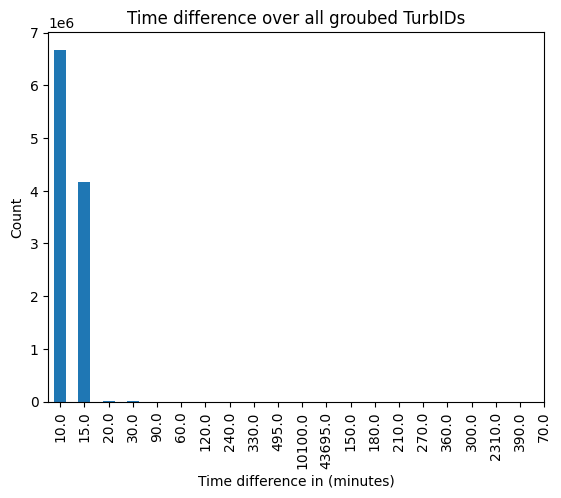

In [8]:
time_diff.value_counts().plot.bar(rot=90)
plt.title('Time difference over all groubed TurbIDs')
plt.ylabel('Count')
plt.xlabel('Time difference in (minutes)')
plt.xlim(-0.5, 20)


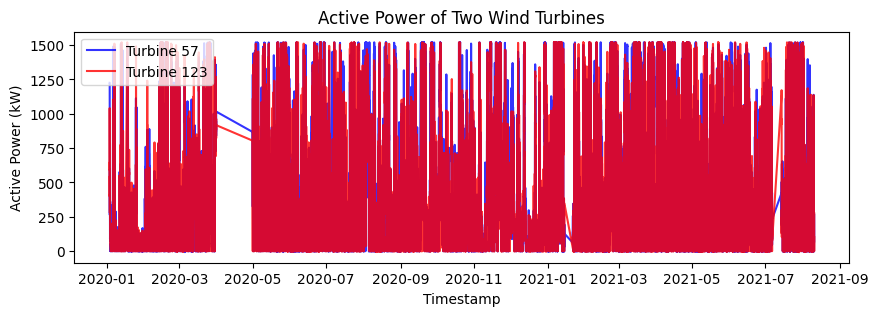

In [9]:

# Filter data for two wind turbines
df_sorted = df_train.sort_values('Tmstamp', inplace=False)
turbine_1 = df_sorted[df_sorted['TurbID'] == 57]
turbine_2 = df_sorted[df_sorted['TurbID'] == 123]

# Plot the active power (Patv) of the two turbines
plt.figure(figsize=(10, 3))
plt.plot(turbine_1['Tmstamp'], turbine_1['Patv'], label='Turbine 57', color='blue', alpha=0.8)
plt.plot(turbine_2['Tmstamp'], turbine_2['Patv'], label='Turbine 123', color='red', alpha=0.8)
plt.xlabel('Timestamp')
plt.ylabel('Active Power (kW)')
plt.title('Active Power of Two Wind Turbines')
plt.legend()


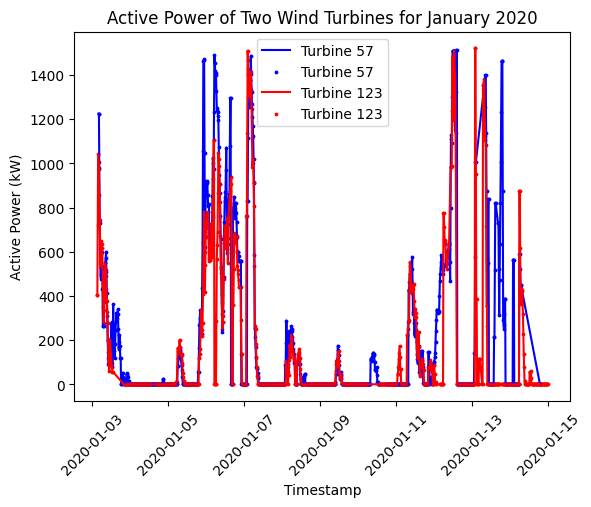

In [10]:
# Filter data for one month (e.g., January 2020)
start_date = '2020-01-01'
end_date = '2020-01-15'
turbine_1_month = turbine_1[(turbine_1['Tmstamp'] >= start_date) & (turbine_1['Tmstamp'] <= end_date)]
turbine_2_month = turbine_2[(turbine_2['Tmstamp'] >= start_date) & (turbine_2['Tmstamp'] <= end_date)]

# Plot the active power (Patv) of the two turbines for one month
plt.figure()
plt.plot(turbine_1_month['Tmstamp'], turbine_1_month['Patv'], label='Turbine 57', color='blue')
plt.scatter(turbine_1_month['Tmstamp'], turbine_1_month['Patv'], s=3, label='Turbine 57', color='blue')
plt.plot(turbine_2_month['Tmstamp'], turbine_2_month['Patv'], label='Turbine 123', color='red')
plt.scatter(turbine_2_month['Tmstamp'], turbine_2_month['Patv'], s=3, label='Turbine 123', color='red')
plt.xlabel('Timestamp')
plt.ylabel('Active Power (kW)')
plt.title('Active Power of Two Wind Turbines for January 2020')
plt.xticks(rotation=45)
plt.legend()


In [11]:
np.sort(df['TurbID'].unique())

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104,
       105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117,
       118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
       131, 132, 133, 134])

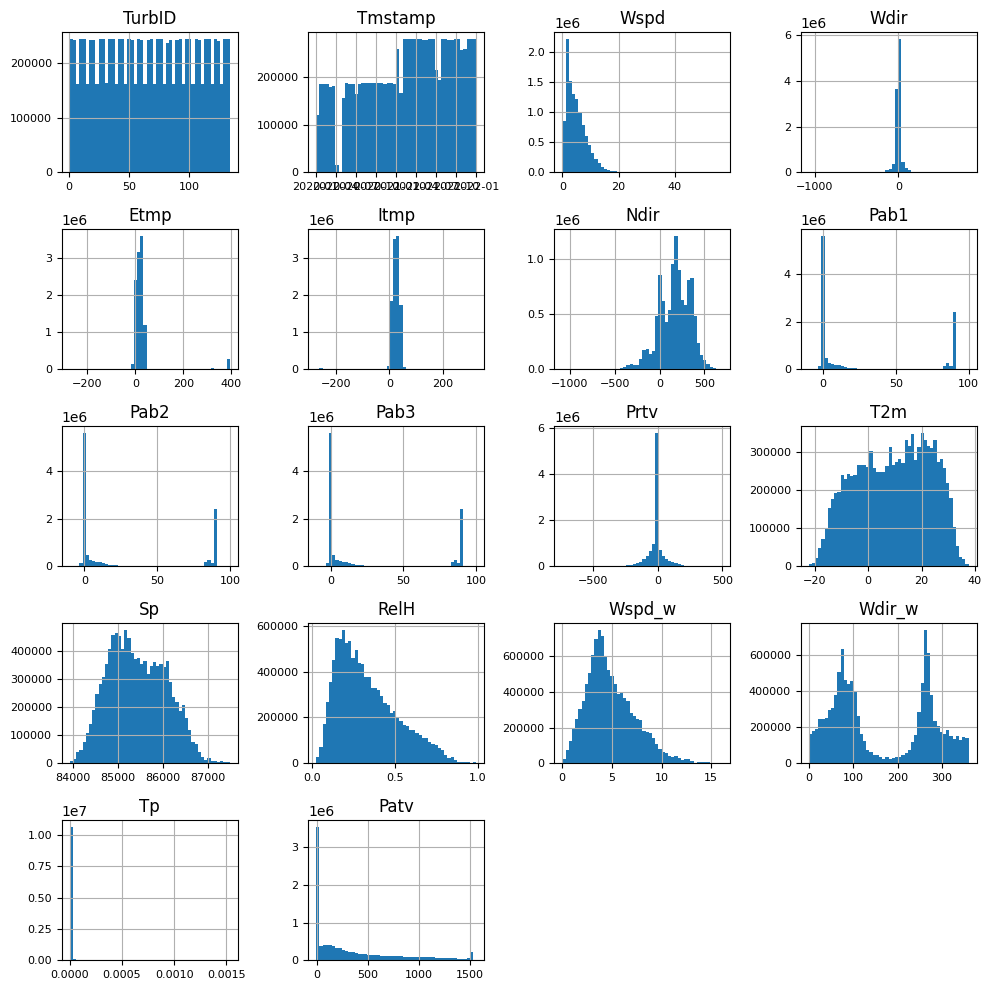

In [12]:
df.hist(figsize=(10, 10), bins=50, xlabelsize=8, ylabelsize=8)
plt.tight_layout()

<Figure size 1000x1000 with 0 Axes>

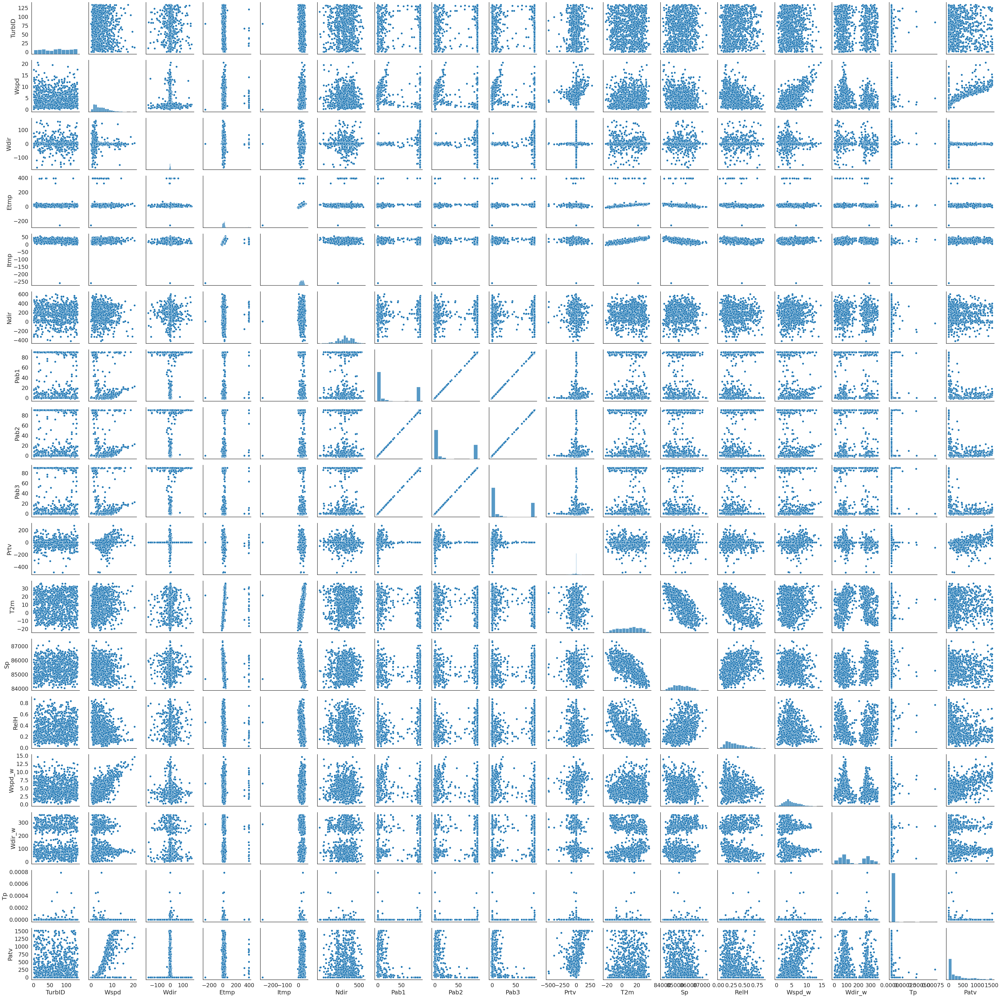

In [13]:
import seaborn as sns

# Plot pair plot for the dataframe
plt.figure(figsize=(10, 10))
with sns.axes_style("white"):
    with sns.plotting_context("notebook", font_scale=1.5):
        sns.pairplot(df.sample(1000))  # Sampling 1000 rows for better performance
plt.show()

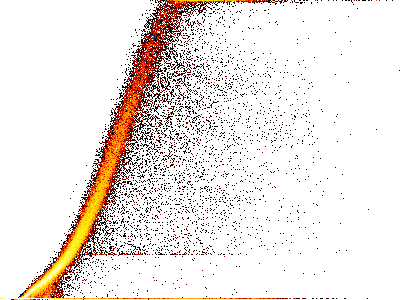

In [14]:
import datashader as ds
import colorcet
import holoviews as hv
import holoviews.operation.datashader as hd

# Filter data for the two turbines
# df_sub = df[(df['TurbID'] == 57) | (df['TurbID'] == 58)]
df_sub = df[(df['TurbID'] == 57)]

# Create a canvas
canvas = ds.Canvas(plot_width=400, plot_height=300)
agg = canvas.points(df_sub, 'Wspd', 'Patv')
img = ds.tf.shade(agg, cmap=colorcet.fire, how='eq_hist')

img

In [7]:
from datashader.mpl_ext import dsshow
%matplotlib inline

plt.figure(figsize=(5,5))
ax = plt.subplot(111)

dsshow(df_sub, ds.Point('Wspd', 'Patv'), norm='eq_hist', cmap="fire", ax=ax, aspect=0.01)
plt.xlabel('Wind Speed (m/s)')
plt.ylabel('Active Power (kW)')

NameError: name 'plt' is not defined

Text(0, 0.5, 'Reaktive Power (kW)')

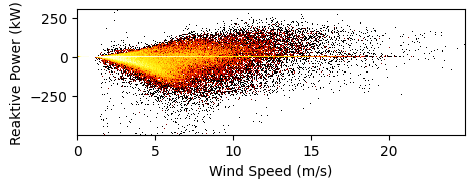

In [ ]:
from datashader.mpl_ext import dsshow
%matplotlib inline

plt.figure(figsize=(5,5))
ax = plt.subplot(111)

dsshow(df_sub, ds.Point('Wspd', 'Prtv'), norm='eq_hist', cmap="fire", ax=ax, aspect=0.01)
plt.xlabel('Wind Speed (m/s)')
plt.ylabel('Reaktive Power (kW)') # Blindleistung

Text(0, 0.5, 'Active Power (kW)')

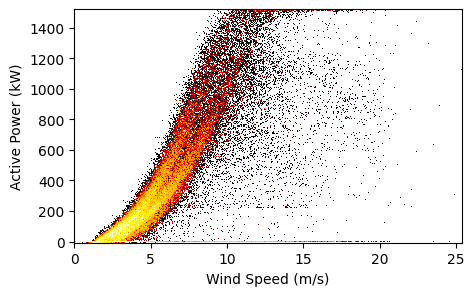

In [ ]:
# Filter data for the two turbines
# df_sub = df[(df['TurbID'] == 57) | (df['TurbID'] == 58)]
df_sub = df[(df['TurbID'] == 120)]

plt.figure(figsize=(5,5))
ax = plt.subplot(111)
dsshow(df_sub, ds.Point('Wspd', 'Patv'), norm='eq_hist', cmap="fire", ax=ax, aspect=0.01)
plt.xlabel('Wind Speed (m/s)')
plt.ylabel('Active Power (kW)')

## Use TimesFM Transformer

In [2]:
import timesfm
import pandas as pd

 See https://github.com/google-research/timesfm/blob/master/README.md for updated APIs.


2025-07-23 11:42:57.593358: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory


Loaded Jax TimesFM, likely because python version is 3.10.16 (main, Dec 11 2024, 16:24:50) [GCC 11.2.0].


### data preparation

In [3]:

jax.profiler.start_server(9999)

In [3]:
# with jax.profiler.trace("tmp_files/profile_data"):

timesfm_backend = "gpu"  # @param
context_length = 160  # 4days 10 minutes resolution, 60 minutes per hour, 24 hours per day
horizon_length = 128    # 1day 10 minutes resolution, 60 minutes per hour, 24 hours per day
batch_size = 16


model = timesfm.TimesFm(
    hparams=timesfm.TimesFmHparams(
        backend=timesfm_backend,
        per_core_batch_size=batch_size,
        horizon_len=horizon_length,
        num_layers=50,
        use_positional_embedding=False,
        context_len=context_length,
        input_patch_len=32,  # not changable for pretrained model
        output_patch_len= 128, # not changable for pretrained model
    ),
    checkpoint=timesfm.TimesFmCheckpoint(
        huggingface_repo_id="google/timesfm-2.0-500m-jax"),
)

def gen_data(rng_seed, context_len, horizon_len, **kwargs):
    path = "datasets/SDWPF/SDWPF_dataset/sdwpf_full/sdwpf_2001_2112_full.parquet"
    df = pd.read_parquet(path)
    df.dropna(inplace=True)

    df.set_index(["TurbID", 'Tmstamp'], inplace=True)
    # standardize the data
    data_mean = df.mean()
    data_std = df.std()
    df = (df - df.mean()) / df.std()
    df = df.reset_index()

    # df_sub = df[(df['TurbID'] == 57)]
    df_sub = df

    df_sub.sort_values(by=["Tmstamp",], inplace=True)
    splits = df_sub['Tmstamp'].quantile([0.75, 0.85, 1.]).values
    # split train test data
    df_train = df_sub[df_sub["Tmstamp"] < splits[0]]
    df_val = df_sub[(df_sub["Tmstamp"] >= splits[0]) & (df_sub["Tmstamp"] < splits[1])]
    df_test = df_sub[df_sub["Tmstamp"] >= splits[1]]

    all_turb_ids = df['TurbID'].unique()
    
    def get_batched_data_fn(df):
        inputs = []
        outputs = []

        num_examples = 0
        for tub_id in all_turb_ids:
            sub_df = df[df["TurbID"] == tub_id]
            for start in range(0, len(sub_df) - (context_len + horizon_len), horizon_len):
                num_examples += 1
                inputs.append(sub_df["Patv"][start:(context_end := start + context_len)].tolist())
                outputs.append(sub_df["Patv"][context_end:(context_end + horizon_len)].tolist())
        return jnp.array(np.array(inputs)), jnp.array(np.array(outputs)), num_examples
    x_train, y_train, _ = get_batched_data_fn(df_train)
    x_val, y_val, _ = get_batched_data_fn(df_val)
    x_test, y_test, _ = get_batched_data_fn(df_test)
    return x_train, y_train, x_val, y_val, x_test, y_test, (data_mean, data_std)

x_train, y_train, x_val, y_val, x_test, y_test, (data_mean, data_std) = gen_data(context_len=context_length, horizon_len=horizon_length, rng_seed=42)



Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Multiprocessing context has already been set.
Constructing model weights.


Constructed model weights in 5.01 seconds.
Restoring checkpoint from /home/daniel/.cache/huggingface/hub/models--google--timesfm-2.0-500m-jax/snapshots/47dedfcadf2abace1cc96071ddb798cfcd3bfcef/checkpoints.


ERROR:absl:For checkpoint version > 1.0, we require users to provide
          `train_state_unpadded_shape_dtype_struct` during checkpoint
          saving/restoring, to avoid potential silent bugs when loading
          checkpoints to incompatible unpadded shapes of TrainState.


Restored checkpoint in 4.96 seconds.
Jitting decoding.
Jitted decoding in 32.92 seconds.


In [4]:
model._train_state.mdl_vars['params']['stacked_transformer_layer']['x_layers_0']['self_attention'].keys()


dict_keys(['key', 'per_dim_scale', 'post', 'query', 'value'])

In [5]:
model._model.model_dims

1280

In [6]:
del x_train, y_train, x_test, y_test

In [42]:
f, s = jax.tree_util.tree_flatten_with_path(model._train_state.mdl_vars['params']['stacked_transformer_layer'])
query_params = 0
values_params = 0
for k,v in f[::-1]:
    name = "/".join((s.key for s in k))  # flatten the path
    print(f"name: {name}, shape: {v.shape},")
    if "query" in name:
        query_params += v.size
    if "value" in name:
        values_params += v.size
print(f"Total query params: {query_params/1e6:.2f}M")
print(f"Total values params: {values_params/1e6:.2f}M")

name: x_layers_9/self_attention/value/w, shape: (1280, 16, 80),
name: x_layers_9/self_attention/value/b, shape: (16, 80),
name: x_layers_9/self_attention/query/w, shape: (1280, 16, 80),
name: x_layers_9/self_attention/query/b, shape: (16, 80),
name: x_layers_9/self_attention/post/w, shape: (1280, 16, 80),
name: x_layers_9/self_attention/post/b, shape: (1280,),
name: x_layers_9/self_attention/per_dim_scale/per_dim_scale, shape: (80,),
name: x_layers_9/self_attention/key/w, shape: (1280, 16, 80),
name: x_layers_9/self_attention/key/b, shape: (16, 80),
name: x_layers_9/layer_norm/scale, shape: (1280,),
name: x_layers_9/ff_layer/layer_norm/scale, shape: (1280,),
name: x_layers_9/ff_layer/layer_norm/bias, shape: (1280,),
name: x_layers_9/ff_layer/ffn_layer2/linear/w, shape: (1280, 1280),
name: x_layers_9/ff_layer/ffn_layer2/bias/b, shape: (1280,),
name: x_layers_9/ff_layer/ffn_layer1/linear/w, shape: (1280, 1280),
name: x_layers_9/ff_layer/ffn_layer1/bias/b, shape: (1280,),
name: x_layers_8

In [ ]:
from timeseries_timesfmToCurve import timesfmWrapper, setup_metrics

model_wrapper = timesfmWrapper(model, frequency=0, autoregressive=False) # learnd output_patchlen was 128. So larger horizon lengths require autoregressive decoding
x_fast, y_fast = x_val[:256], y_val[:256]

In [5]:
# x_val = x_val[:(x_val.shape[0]// 256) * 256]
# y_val = y_val[:(x_val.shape[0]// 256) * 256]

In [6]:
x_fast, y_fast = x_val[:256], y_val[:256]

In [7]:
from src.subspace_curve import QuantileSubspace, filter_mask

s_model = QuantileSubspace(model=model_wrapper, k=2, weight_decay=0., 
                            quantiles=model._model.quantiles,
                            perm_spec=None,
                            natural_parameterization=False,
                            mutuable_param_name = False)
valid_metrics_fn = setup_metrics(s_model, len(x_fast), x_fast, y_fast, n_samples=2)

mask = s_model.init_mask(x_val[:10], all_curves=False)
# mask = filter_mask(mask, 'key', 'layer_norm', 'per_dim_scale', as_curve=False, BoolschenOperator=any)
mask = filter_mask(mask, "value", "x_layers_0", as_curve=True, BoolschenOperator=all)
init_params = model._train_state.mdl_vars
params = s_model.init_params_from_point(random.PRNGKey(0), init_params, mask, jitter=1e-8)
# params['params']['stacked_transformer_layer']['x_layers_0']['self_attention']['query']['w'].block_until_ready()


In [16]:
params['params']['stacked_transformer_layer']['x_layers_0']['self_attention']['query']['w']

array([[[-0.01373756, -0.0113514 , -0.01692239, ..., -0.00058819,
         -0.01410772,  0.01377986],
        [ 0.03799576, -0.02763489, -0.0305728 , ..., -0.03779376,
         -0.02462143,  0.02604621],
        [-0.00544646, -0.00529829, -0.00044794, ..., -0.00157182,
         -0.00173163,  0.02930193],
        ...,
        [ 0.01351677, -0.00394501, -0.0078214 , ...,  0.00992586,
          0.0002521 , -0.01098836],
        [-0.01537517, -0.02596941, -0.01750917, ...,  0.02113295,
          0.01223158,  0.01281489],
        [-0.00292578,  0.01452295,  0.02519316, ...,  0.01794215,
         -0.00916221, -0.00377409]],

       [[ 0.00085703,  0.00931211,  0.02315098, ...,  0.00093921,
          0.01030863,  0.00983754],
        [ 0.00333646, -0.01759784, -0.01200169, ..., -0.00019083,
         -0.01691269,  0.00179599],
        [-0.00222223, -0.00286643, -0.00940596, ...,  0.01017399,
          0.00733768, -0.01340178],
        ...,
        [ 0.00266873, -0.00045358,  0.00093327, ...,  

In [8]:
n_params = sum(p.size for p in jax.tree.flatten(params)[0])
print(f"Number of parameters: {n_params:,}")

Number of parameters: 502,108,320


In [24]:
path_values, structure = jax.tree_util.tree_flatten_with_path(mask)
for i, (k, v) in enumerate(path_values):
    path = "/".join((dk.key for dk in k))
    print(path)

freq_emb/emb_var
horizon_ff_layer/hidden_layer/bias/b
horizon_ff_layer/hidden_layer/linear/w
horizon_ff_layer/output_layer/bias/b
horizon_ff_layer/output_layer/linear/w
horizon_ff_layer/residual_layer/bias/b
horizon_ff_layer/residual_layer/linear/w
input_ff_layer/hidden_layer/bias/b
input_ff_layer/hidden_layer/linear/w
input_ff_layer/output_layer/bias/b
input_ff_layer/output_layer/linear/w
input_ff_layer/residual_layer/bias/b
input_ff_layer/residual_layer/linear/w
stacked_transformer_layer/x_layers_0/ff_layer/ffn_layer1/bias/b
stacked_transformer_layer/x_layers_0/ff_layer/ffn_layer1/linear/w
stacked_transformer_layer/x_layers_0/ff_layer/ffn_layer2/bias/b
stacked_transformer_layer/x_layers_0/ff_layer/ffn_layer2/linear/w
stacked_transformer_layer/x_layers_0/ff_layer/layer_norm/bias
stacked_transformer_layer/x_layers_0/ff_layer/layer_norm/scale
stacked_transformer_layer/x_layers_0/layer_norm/scale
stacked_transformer_layer/x_layers_0/self_attention/key/b
stacked_transformer_layer/x_layers

In [ ]:
from src.subspace_curve import filter_mask
mask = filter_mask(mask, 'key', as_curve=False)

In [9]:
mask['stacked_transformer_layer']['x_layers_10']['self_attention']['key']['b']

False

In [16]:
jax.tree.map(lambda x:not x, mask)

{'freq_emb': {'emb_var': True},
 'horizon_ff_layer': {'hidden_layer': {'bias': {'b': True},
   'linear': {'w': True}},
  'output_layer': {'bias': {'b': True}, 'linear': {'w': True}},
  'residual_layer': {'bias': {'b': True}, 'linear': {'w': True}}},
 'input_ff_layer': {'hidden_layer': {'bias': {'b': True},
   'linear': {'w': True}},
  'output_layer': {'bias': {'b': True}, 'linear': {'w': True}},
  'residual_layer': {'bias': {'b': True}, 'linear': {'w': True}}},
 'stacked_transformer_layer': {'x_layers_0': {'ff_layer': {'ffn_layer1': {'bias': {'b': True},
     'linear': {'w': True}},
    'ffn_layer2': {'bias': {'b': True}, 'linear': {'w': True}},
    'layer_norm': {'bias': True, 'scale': True}},
   'layer_norm': {'scale': True},
   'self_attention': {'key': {'b': True, 'w': True},
    'per_dim_scale': {'per_dim_scale': True},
    'post': {'b': True, 'w': True},
    'query': {'b': True, 'w': True},
    'value': {'b': False, 'w': False}}},
  'x_layers_1': {'ff_layer': {'ffn_layer1': {'bia

In [22]:
            
loss, mse = valid_metrics_fn(random.PRNGKey(0), params)
loss, mse

out shape: (256, 128, 10)
out shape: (256, 128, 10)


(Array(6.76254, dtype=float32), Array(1.1191239, dtype=float32))

In [14]:
params

{'params': {'freq_emb': {'emb_var': Array([[[ 0.09498979, -0.03221983, -0.05389087, ..., -0.12183158,
             0.08854849,  0.00628476],
           [ 0.1048953 , -0.06185807,  0.08863155, ..., -0.02630783,
             0.03747938, -0.11830091],
           [ 0.01713165,  0.07226092,  0.0259877 , ...,  0.08966532,
             0.06762085, -0.05112474]]], dtype=float32)},
  'horizon_ff_layer': {'hidden_layer': {'bias': {'b': Array([[-0.0192185 , -0.04716438, -0.01817103, ..., -0.04556634,
             -0.03470362, -0.0344962 ]], dtype=float32)},
    'linear': {'w': Array([[[ 0.03655546,  0.01540518, -0.04364083, ..., -0.01548328,
              -0.07610342, -0.01170965],
             [-0.09271821,  0.03270155, -0.04432857, ..., -0.04764685,
              -0.02035582,  0.01599863],
             [-0.01994627, -0.01941311, -0.0329221 , ..., -0.03584743,
              -0.05884511,  0.00292653],
             ...,
             [-0.0088599 ,  0.00132444, -0.01011134, ...,  0.05623167,
       

In [1]:
x_train[:batch_size].shape

NameError: name 'x_train' is not defined

In [17]:
batch_size

16

In [20]:
optax.__version__

'0.2.2'

In [15]:
import optax
optimizer = optax.chain(optax.sgd(learning_rate=0.001, momentum=0.9, nesterov=True), 
                        optax.masked(optax.set_to_zero(), jax.tree.map(lambda x:not x, mask)))
# optimizer = optax.sgd(learning_rate=0.001, momentum=0.9, nesterov=True)
opt_state = optimizer.init(params['params'])  # only dnn parameters
loss, params, opt_state, grad_ = s_model.train_step(
                    random.PRNGKey(0), params, x_fast[:batch_size], y_fast[:batch_size], opt_state, optimizer)
# jax.profiler.save_device_memory_profile("memory_profile/memory3.prof")

In [16]:
params['params']['stacked_transformer_layer']['x_layers_0']['self_attention']['query']['b']

Array([[ 0.11062208,  0.34942016,  0.12388793, ..., -0.04500244,
         0.01217891, -0.25200027],
       [ 0.34703657, -0.38526252, -0.33235297, ..., -0.33756825,
        -0.4956135 ,  0.41656825],
       [ 0.10087154,  0.17263292,  0.22066864, ..., -0.06233025,
        -0.01552925,  0.22420064],
       ...,
       [ 0.17617932, -0.18099512, -0.11331107, ..., -0.01913172,
         0.24133584, -0.08077607],
       [-0.3963601 , -0.3458859 , -0.35823902, ...,  0.44237605,
         0.26450336,  0.24553123],
       [ 0.21099633, -0.06967792,  0.27273047, ..., -0.05524346,
        -0.12684175,  0.13932739]], dtype=float32)

In [ ]:
params['params']['stacked_transformer_layer']['x_layers_0']['self_attention']['query']['b']

Array([[ 0.11062208,  0.34942016,  0.12388793, ..., -0.04500244,
         0.01217891, -0.25200027],
       [ 0.34703657, -0.38526252, -0.33235297, ..., -0.33756825,
        -0.4956135 ,  0.41656825],
       [ 0.10087154,  0.17263292,  0.22066864, ..., -0.06233025,
        -0.01552925,  0.22420064],
       ...,
       [ 0.17617932, -0.18099512, -0.11331107, ..., -0.01913172,
         0.24133584, -0.08077607],
       [-0.3963601 , -0.3458859 , -0.35823902, ...,  0.44237605,
         0.26450336,  0.24553123],
       [ 0.21099633, -0.06967792,  0.27273047, ..., -0.05524346,
        -0.12684175,  0.13932739]], dtype=float32)

In [17]:
params['params']['stacked_transformer_layer']['x_layers_0']['self_attention']['value']['b']

Array([[[ 0.05495905, -0.03288056, -0.03067696, ..., -0.09473903,
          0.0714647 ,  0.13616146],
        [-0.19873855,  0.14761151, -0.0423241 , ...,  0.08310484,
         -0.11828659, -0.00114524],
        [-0.17772721, -0.23678878, -0.40474057, ...,  0.27986374,
         -0.21768972, -0.14250953],
        ...,
        [-0.06038664,  0.10711683,  0.13057691, ...,  0.14380112,
         -0.00259882,  0.06232868],
        [-0.22388254, -0.1937886 ,  0.24483879, ..., -0.01075725,
         -0.08286789, -0.03840655],
        [ 0.18786417, -0.04248397,  0.18853426, ...,  0.06010745,
         -0.150785  ,  0.07440924]],

       [[ 0.05494082, -0.03287733, -0.03066849, ..., -0.09474152,
          0.07144968,  0.13616486],
        [-0.19874077,  0.14760321, -0.04232614, ...,  0.08310182,
         -0.11829148, -0.00114689],
        [-0.17769842, -0.23678908, -0.4047523 , ...,  0.27986464,
         -0.21766065, -0.14251438],
        ...,
        [-0.06034603,  0.10709502,  0.1305796 , ...,  

In [ ]:
params['params']['stacked_transformer_layer']['x_layers_0']['self_attention']['value']['b']

Array([[[ 0.05499296, -0.03287918, -0.03069447, ..., -0.09473599,
          0.07147468,  0.1361577 ],
        [-0.19872993,  0.14761518, -0.04232161, ...,  0.08310863,
         -0.11827821, -0.00114599],
        [-0.17774062, -0.2367884 , -0.40473795, ...,  0.2798657 ,
         -0.21770643, -0.14250256],
        ...,
        [-0.06045906,  0.10715142,  0.13057408, ...,  0.1437998 ,
         -0.00259726,  0.0622699 ],
        [-0.22387852, -0.19378792,  0.2448281 , ..., -0.01075528,
         -0.08286766, -0.03840695],
        [ 0.18789035, -0.04248368,  0.18853061, ...,  0.06008593,
         -0.1508039 ,  0.07444035]],

       [[ 0.05498962, -0.03287535, -0.03069369, ..., -0.09473714,
          0.07146405,  0.13615943],
        [-0.19872838,  0.14760849, -0.04232258, ...,  0.08310729,
         -0.11827942, -0.00114797],
        [-0.1777177 , -0.23678856, -0.4047485 , ...,  0.27986747,
         -0.21768469, -0.14250432],
        ...,
        [-0.06045025,  0.10714479,  0.13057554, ...,  

In [9]:
def masked_pytree_to_matrix(pytree, mask, k):
    """
    Converts a pytree of the subspace model into a matrix.

    Args:
        pytree: The pytree to be converted.

    Returns:
        matrix: The matrix representation of the pytree with shape (k+1, n_params).
    """
    # first argument of reduce fn is the accumulator and second is the current value
    only_curve_params = jax.tree.map(lambda x, m: x if m else jnp.reshape(jnp.array([]), (k+1, 0)), pytree, mask)
    return jax.tree.reduce(lambda x, y: jnp.concatenate(
        [x.reshape(k+1, -1), y.reshape(k+1, -1)], axis=-1), only_curve_params)

In [11]:
# from src.subspace_curve import masked_pytree_to_matrix

cp = masked_pytree_to_matrix(params['params']['input_ff_layer'], s_model.curve_mask['input_ff_layer'], k=2)
cp.shape

(3, 1806080)

In [10]:
df_mean

NameError: name 'df_mean' is not defined

In [38]:
import gc
# model._train_state.mdl_vars['params'] = None
gc.collect()

1437

In [17]:

shuffel = jax.random.permutation(random.PRNGKey(0), jnp.arange(y_train.shape[0]))
x_train = x_train[shuffel]
from einshape import jax_einshape as es

x = x_train[:(x_train.shape[0]// 256) * 256]
es('(ib)...->ib...', x, b=256).shape


(106, 256, 2304)

AttributeError: 'jaxlib.xla_extension.DeviceList' object has no attribute 'numpy'

In [ ]:
model_wrapper.apply(x_train[:256], y_train[:256], training=True, return_outputs=True, return_loss=True, return_metrics=True)

In [12]:
mean_forecast, quantile_forecast = model.forecast(inputs, freq=[2,]*len(inputs), normalize=False)

In [13]:
mean_forecast_val, quantile_forecast_val = model.forecast(inputs_val, freq=[2,]*len(inputs_val), normalize=False)

In [7]:
model._model.quantiles

(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)

In [29]:
aa = jnp.ones((13,20,9))

{'quantile': model._model.quantiles, 'preds': aa.transpose(2, 0, 1)}

{'quantile': (0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9),
 'preds': Array([[[1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.],
         ...,
         [1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.]],
 
        [[1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.],
         ...,
         [1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.]],
 
        [[1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.],
         ...,
         [1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.]],
 
        ...,
 
        [[1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.],
         ...,
         [1

In [20]:
aa.transpose(2, 0, 1).shape

(10, 13, 20)

In [34]:
jnp.array(model._model.quantiles).shape

(9,)

In [66]:
def _quantile_loss(pred, actual, quantile: float):
        """Calculates quantile loss.

        Args:
        pred: B x T
        actual: B x T
        quantile: quantile at which loss is computed.

        Returns:
        per coordinate loss.
        """
        dev = actual - pred
        loss_first = dev * quantile
        loss_second = -dev * (1.0 - quantile)
        return 2 * jnp.where(loss_first >= 0, loss_first, loss_second)

y = jnp.zeros((3,2))
aa = jnp.tile(jnp.arange(-5,5,1.), (3,2,1)) * jnp.array((-0.5,1,1.5))[:,None,None]
loss = jnp.square(aa[:,:,0] - y)

def body_fun(loss, pred_and_quantile):
    loss += _quantile_loss(pred_and_quantile['preds'], y, quantile=pred_and_quantile['quantile'])
    return loss, _

loss, _ = jax.lax.scan(body_fun, loss, {'quantile': jnp.array(model._model.quantiles), 'preds': aa.transpose(2, 0, 1)[1:]})
loss


Array([[22.25, 22.25],
       [33.  , 33.  ],
       [68.25, 68.25]], dtype=float32)

In [13]:
inputs.shape

(4556, 2304)

In [14]:
# prediction with Year frequency
mean_forecast, quantile_forecast = model.forecast(inputs, freq=[2,]*len(inputs), normalize=False)
mean_forecast.shape, quantile_forecast.shape

((4556, 288), (4556, 288, 10))

In [15]:
mse = jnp.mean((mean_forecast - outputs) ** 2, axis=-1)
print("MSE Error: ", mse.mean())

MSE Error:  0.82922924


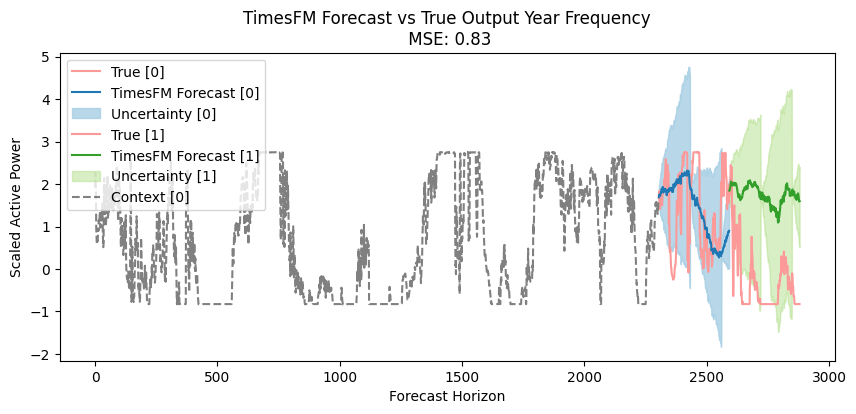

In [16]:
cmap = plt.get_cmap('Paired')
plt.figure(figsize=(10, 4))
plt.plot(np.arange(context_length, context_length+horizon_length), outputs[0], label='True [0]', color=cmap(4))
plt.plot(np.arange(context_length, context_length+horizon_length), mean_forecast[0], label='TimesFM Forecast [0]', color=cmap(1))
plt.fill_between(np.arange(context_length, context_length+horizon_length),
                 quantile_forecast[0, :, 1], quantile_forecast[0, :, 9],
                 color=cmap(0), alpha=0.8, label='Uncertainty [0]')
plt.plot(np.arange(context_length+horizon_length, context_length+2*horizon_length), outputs[1], label='True [1]', color=cmap(4))
plt.plot(np.arange(context_length+horizon_length, context_length+2*horizon_length), mean_forecast[1], label='TimesFM Forecast [1]', color=cmap(3))
plt.fill_between(np.arange(context_length+horizon_length, context_length+2*horizon_length),
                 quantile_forecast[1, :, 1], quantile_forecast[1, :, 9],
                 color=cmap(2), alpha=0.5, label='Uncertainty [1]')
plt.plot(inputs[0], label='Context [0]', linestyle='--', color='gray')
plt.xlabel('Forecast Horizon')
plt.ylabel('Scaled Active Power')
plt.title('TimesFM Forecast vs True Output Year Frequency\n MSE: {:.2f}'.format(mse.mean()))
plt.legend()

MSE Error:  0.78196603


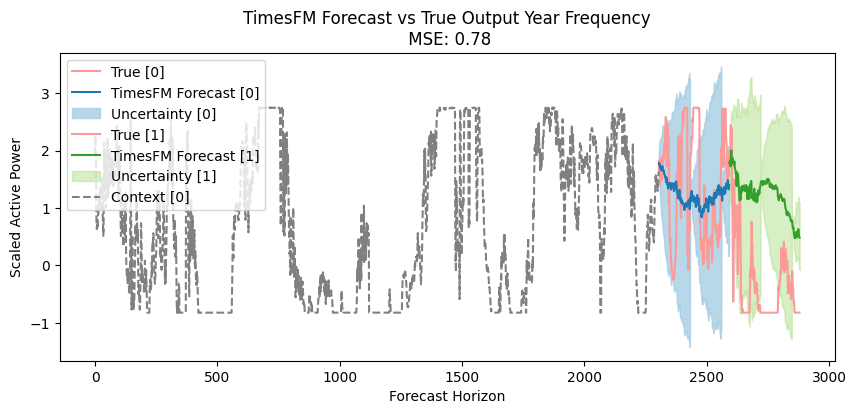

In [17]:
# prediction with Week, Month frequency
mean_forecast, quantile_forecast = model.forecast(inputs, freq=[1,]*len(inputs), normalize=False)
mean_forecast.shape, quantile_forecast.shape
mse = jnp.mean((mean_forecast - outputs) ** 2, axis=-1)
print("MSE Error: ", mse.mean())

cmap = plt.get_cmap('Paired')
plt.figure(figsize=(10, 4))
plt.plot(np.arange(context_length, context_length+horizon_length), outputs[0], label='True [0]', color=cmap(4))
plt.plot(np.arange(context_length, context_length+horizon_length), mean_forecast[0], label='TimesFM Forecast [0]', color=cmap(1))
plt.fill_between(np.arange(context_length, context_length+horizon_length),
                 quantile_forecast[0, :, 1], quantile_forecast[0, :, 9],
                 color=cmap(0), alpha=0.8, label='Uncertainty [0]')
plt.plot(np.arange(context_length+horizon_length, context_length+2*horizon_length), outputs[1], label='True [1]', color=cmap(4))
plt.plot(np.arange(context_length+horizon_length, context_length+2*horizon_length), mean_forecast[1], label='TimesFM Forecast [1]', color=cmap(3))
plt.fill_between(np.arange(context_length+horizon_length, context_length+2*horizon_length),
                 quantile_forecast[1, :, 1], quantile_forecast[1, :, 9],
                 color=cmap(2), alpha=0.5, label='Uncertainty [1]')
plt.plot(inputs[0], label='Context [0]', linestyle='--', color='gray')
plt.xlabel('Forecast Horizon')
plt.ylabel('Scaled Active Power')
plt.title('TimesFM Forecast vs True Output Month Frequency\n MSE: {:.2f}'.format(mse.mean()))
plt.legend()

MSE Error:  0.69887257


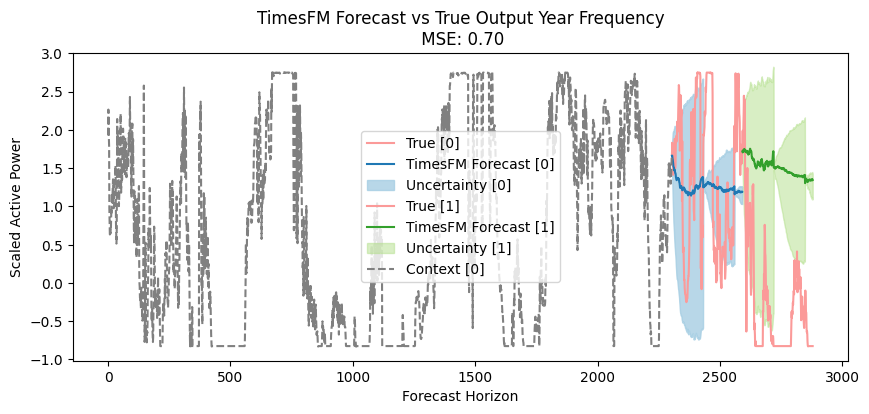

In [18]:
# prediction with Hour/ Day frequency
mean_forecast, quantile_forecast = model.forecast(inputs, freq=[0,]*len(inputs), normalize=False)
mean_forecast.shape, quantile_forecast.shape
mse = jnp.mean((mean_forecast - outputs) ** 2, axis=-1)
print("MSE Error: ", mse.mean())

cmap = plt.get_cmap('Paired')
plt.figure(figsize=(10, 4))
plt.plot(np.arange(context_length, context_length+horizon_length), outputs[0], label='True [0]', color=cmap(4))
plt.plot(np.arange(context_length, context_length+horizon_length), mean_forecast[0], label='TimesFM Forecast [0]', color=cmap(1))
plt.fill_between(np.arange(context_length, context_length+horizon_length),
                 quantile_forecast[0, :, 1], quantile_forecast[0, :, 9],
                 color=cmap(0), alpha=0.8, label='Uncertainty [0]')
plt.plot(np.arange(context_length+horizon_length, context_length+2*horizon_length), outputs[1], label='True [1]', color=cmap(4))
plt.plot(np.arange(context_length+horizon_length, context_length+2*horizon_length), mean_forecast[1], label='TimesFM Forecast [1]', color=cmap(3))
plt.fill_between(np.arange(context_length+horizon_length, context_length+2*horizon_length),
                 quantile_forecast[1, :, 1], quantile_forecast[1, :, 9],
                 color=cmap(2), alpha=0.5, label='Uncertainty [1]')
plt.plot(inputs[0], label='Context [0]', linestyle='--', color='gray')
plt.xlabel('Forecast Horizon')
plt.ylabel('Scaled Active Power')
plt.title('TimesFM Forecast vs True Output Day Frequency\n MSE: {:.2f}'.format(mse.mean()))
plt.legend()

## TimesFM with Curve and LoRA

In [2]:
import timesfm
import pandas as pd

# with jax.profiler.trace("tmp_files/profile_data"):

timesfm_backend = "gpu"  # @param
context_length = 160  # 4days 10 minutes resolution, 60 minutes per hour, 24 hours per day
horizon_length = 128    # 1day 10 minutes resolution, 60 minutes per hour, 24 hours per day
batch_size = 16


model = timesfm.TimesFm(
    hparams=timesfm.TimesFmHparams(
        backend=timesfm_backend,
        per_core_batch_size=batch_size,
        horizon_len=horizon_length,
        num_layers=50,
        use_positional_embedding=False,
        context_len=context_length,
        input_patch_len=32,  # not changable for pretrained model
        output_patch_len= 128, # not changable for pretrained model
    ),
    checkpoint=timesfm.TimesFmCheckpoint(
        huggingface_repo_id="google/timesfm-2.0-500m-jax"),
)

def gen_data(rng_seed, context_len, horizon_len, **kwargs):
    path = "datasets/SDWPF/SDWPF_dataset/sdwpf_full/sdwpf_2001_2112_full.parquet"
    df = pd.read_parquet(path)
    df.dropna(inplace=True)

    df.set_index(["TurbID", 'Tmstamp'], inplace=True)
    # standardize the data
    data_mean = df.mean()
    data_std = df.std()
    df = (df - df.mean()) / df.std()
    df = df.reset_index()

    # df_sub = df[(df['TurbID'] == 57)]
    df_sub = df

    df_sub.sort_values(by=["Tmstamp",], inplace=True)
    splits = df_sub['Tmstamp'].quantile([0.75, 0.85, 1.]).values
    # split train test data
    df_train = df_sub[df_sub["Tmstamp"] < splits[0]]
    df_val = df_sub[(df_sub["Tmstamp"] >= splits[0]) & (df_sub["Tmstamp"] < splits[1])]
    df_test = df_sub[df_sub["Tmstamp"] >= splits[1]]

    all_turb_ids = df['TurbID'].unique()
    
    def get_batched_data_fn(df):
        inputs = []
        outputs = []

        num_examples = 0
        for tub_id in all_turb_ids:
            sub_df = df[df["TurbID"] == tub_id]
            for start in range(0, len(sub_df) - (context_len + horizon_len), horizon_len):
                num_examples += 1
                inputs.append(sub_df["Patv"][start:(context_end := start + context_len)].tolist())
                outputs.append(sub_df["Patv"][context_end:(context_end + horizon_len)].tolist())
        return jnp.array(np.array(inputs)), jnp.array(np.array(outputs)), num_examples
    x_train, y_train, _ = get_batched_data_fn(df_train)
    x_val, y_val, _ = get_batched_data_fn(df_val)
    x_test, y_test, _ = get_batched_data_fn(df_test)
    return x_train, y_train, x_val, y_val, x_test, y_test, (data_mean, data_std)

x_train, y_train, x_val, y_val, x_test, y_test, (data_mean, data_std) = gen_data(context_len=context_length, horizon_len=horizon_length, rng_seed=42)



 See https://github.com/google-research/timesfm/blob/master/README.md for updated APIs.


2025-07-23 17:07:10.261572: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory


Loaded Jax TimesFM, likely because python version is 3.10.16 (main, Dec 11 2024, 16:24:50) [GCC 11.2.0].


Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Multiprocessing context has already been set.
Constructing model weights.


Constructed model weights in 5.19 seconds.
Restoring checkpoint from /home/daniel/.cache/huggingface/hub/models--google--timesfm-2.0-500m-jax/snapshots/47dedfcadf2abace1cc96071ddb798cfcd3bfcef/checkpoints.


ERROR:absl:For checkpoint version > 1.0, we require users to provide
          `train_state_unpadded_shape_dtype_struct` during checkpoint
          saving/restoring, to avoid potential silent bugs when loading
          checkpoints to incompatible unpadded shapes of TrainState.


Restored checkpoint in 2.07 seconds.
Jitting decoding.
Jitted decoding in 30.09 seconds.


In [3]:
from timeseries_timesfmToCurve import timesfmWrapper, setup_metrics

model_wrapper = timesfmWrapper(model, frequency=0, autoregressive=False) # learnd output_patchlen was 128. So larger horizon lengths require autoregressive decoding
x_fast, y_fast = x_val[:256], y_val[:256]

In [4]:
model._train_state.mdl_vars['params']['stacked_transformer_layer']['x_layers_0']['self_attention'].keys()

dict_keys(['key', 'per_dim_scale', 'post', 'query', 'value'])

In [5]:
print("query weights shape:")
model._train_state.mdl_vars['params']['stacked_transformer_layer']['x_layers_0']['self_attention']['query']['w'].shape

query weights shape:


(1280, 16, 80)

In [17]:
from src.subspace_curve import QuantileSubspace, filter_mask, LoRAMixin

class LoraQuantileSubspace(LoRAMixin, QuantileSubspace):
    pass

base_params = model._train_state.mdl_vars
curve_mask = jax.tree.map(lambda x: False, base_params['params'])
curve_mask = filter_mask(curve_mask, 'query', as_curve=True, BoolschenOperator=all)
train_mask = jax.tree.map(lambda x: False, base_params['params'])
train_mask = filter_mask(train_mask, 'query', as_curve=True, BoolschenOperator=all)
lora_mask = jax.tree.map(lambda x: False, base_params['params'])  # LoRA mask for all parameters
lora_mask = filter_mask(lora_mask, 'query', 'w', as_curve=True, BoolschenOperator=all)  # LoRA for query parameters only
lora_mask = jax.tree.map(lambda m: np.array([0,2]) if m else m, lora_mask)  # LoRA for curve parameters only

s_model = LoraQuantileSubspace(lora_mask=lora_mask, r=8,
                               model=model_wrapper, k=2, weight_decay=0., 
                               quantiles=model._model.quantiles,
                               perm_spec=None,
                               natural_parameterization=False,
                               mutuable_param_name = False)

# valid_metrics_fn = setup_metrics(s_model, len(x_fast), x_fast, y_fast, n_samples=2)

fan_in = 1280. * 16
params = s_model.init_params_from_point(random.PRNGKey(0), base_params, curve_mask, jitter=np.sqrt(2./fan_in, dtype=np.float32))

train_mask = s_model.update_mask_for_lora(train_mask, params['params'], b_off=False, w0_off=True) # w0 must be off for LoRA 
s_model.set_train_mask(train_mask)
# params['params']['stacked_transformer_layer']['x_layers_0']['self_attention']['query']['w'].block_until_ready()


In [18]:
s_model.train_mask

{'freq_emb': {'emb_var': False},
 'horizon_ff_layer': {'hidden_layer': {'bias': {'b': False},
   'linear': {'w': False}},
  'output_layer': {'bias': {'b': False}, 'linear': {'w': False}},
  'residual_layer': {'bias': {'b': False}, 'linear': {'w': False}}},
 'input_ff_layer': {'hidden_layer': {'bias': {'b': False},
   'linear': {'w': False}},
  'output_layer': {'bias': {'b': False}, 'linear': {'w': False}},
  'residual_layer': {'bias': {'b': False}, 'linear': {'w': False}}},
 'stacked_transformer_layer': {'x_layers_0': {'ff_layer': {'ffn_layer1': {'bias': {'b': False},
     'linear': {'w': False}},
    'ffn_layer2': {'bias': {'b': False}, 'linear': {'w': False}},
    'layer_norm': {'bias': False, 'scale': False}},
   'layer_norm': {'scale': False},
   'self_attention': {'key': {'b': False, 'w': False},
    'per_dim_scale': {'per_dim_scale': False},
    'post': {'b': False, 'w': False},
    'query': {'b': True,
     'w': LoRAParams(A=True, B=True, w0=False) with dims=(0, 2))},
    'value

In [19]:
lora_mask

{'freq_emb': {'emb_var': False},
 'horizon_ff_layer': {'hidden_layer': {'bias': {'b': False},
   'linear': {'w': False}},
  'output_layer': {'bias': {'b': False}, 'linear': {'w': False}},
  'residual_layer': {'bias': {'b': False}, 'linear': {'w': False}}},
 'input_ff_layer': {'hidden_layer': {'bias': {'b': False},
   'linear': {'w': False}},
  'output_layer': {'bias': {'b': False}, 'linear': {'w': False}},
  'residual_layer': {'bias': {'b': False}, 'linear': {'w': False}}},
 'stacked_transformer_layer': {'x_layers_0': {'ff_layer': {'ffn_layer1': {'bias': {'b': False},
     'linear': {'w': False}},
    'ffn_layer2': {'bias': {'b': False}, 'linear': {'w': False}},
    'layer_norm': {'bias': False, 'scale': False}},
   'layer_norm': {'scale': False},
   'self_attention': {'key': {'b': False, 'w': False},
    'per_dim_scale': {'per_dim_scale': False},
    'post': {'b': False, 'w': False},
    'query': {'b': False, 'w': array([0, 2])},
    'value': {'b': False, 'w': False}}},
  'x_layers_1'

In [20]:
s_model.curve_mask

{'freq_emb': {'emb_var': False},
 'horizon_ff_layer': {'hidden_layer': {'bias': {'b': False},
   'linear': {'w': False}},
  'output_layer': {'bias': {'b': False}, 'linear': {'w': False}},
  'residual_layer': {'bias': {'b': False}, 'linear': {'w': False}}},
 'input_ff_layer': {'hidden_layer': {'bias': {'b': False},
   'linear': {'w': False}},
  'output_layer': {'bias': {'b': False}, 'linear': {'w': False}},
  'residual_layer': {'bias': {'b': False}, 'linear': {'w': False}}},
 'stacked_transformer_layer': {'x_layers_0': {'ff_layer': {'ffn_layer1': {'bias': {'b': False},
     'linear': {'w': False}},
    'ffn_layer2': {'bias': {'b': False}, 'linear': {'w': False}},
    'layer_norm': {'bias': False, 'scale': False}},
   'layer_norm': {'scale': False},
   'self_attention': {'key': {'b': False, 'w': False},
    'per_dim_scale': {'per_dim_scale': False},
    'post': {'b': False, 'w': False},
    'query': {'b': True,
     'w': LoRAParams(A=True, B=False, w0=False) with dims=(0, 2))},
    'valu

In [21]:
params['params']['stacked_transformer_layer']['x_layers_0']['self_attention']['query']['w'].shape

{'A': (3, 16, 8, 80), 'B': (16, 1280, 8), 'w0': (1280, 16, 80)}

In [22]:
jax.tree.flatten(params['params']['stacked_transformer_layer']['x_layers_0']['self_attention']['query'])

([Array([[[ 0.11088362,  0.35785708,  0.13003352, ..., -0.04969892,
            0.01034865, -0.25497434],
          [ 0.33672938, -0.38551942, -0.32671243, ..., -0.33959106,
           -0.48595378,  0.4282248 ],
          [ 0.09126233,  0.1794342 ,  0.21501824, ..., -0.06067778,
           -0.01050724,  0.20715933],
          ...,
          [ 0.18890159, -0.16000508, -0.10807773, ..., -0.01834927,
            0.22705148, -0.06888649],
          [-0.39220533, -0.3490848 , -0.36810035, ...,  0.4211008 ,
            0.26507992,  0.24433628],
          [ 0.21293734, -0.06105028,  0.27511704, ..., -0.05744978,
           -0.1418412 ,  0.15219897]],
  
         [[ 0.10370621,  0.3421217 ,  0.11916687, ..., -0.03108296,
            0.02723465, -0.23862357],
          [ 0.34739572, -0.39648488, -0.33421463, ..., -0.3409694 ,
           -0.50100803,  0.4218865 ],
          [ 0.11645024,  0.17608039,  0.22961786, ..., -0.06837863,
           -0.02120284,  0.22874865],
          ...,
          [ 

In [23]:
only_train_params = s_model.only_trainable_params(params['params'])
print(f"Number for trainable params: {np.sum([l.size for l in jax.tree.leaves(only_train_params)]):_}")
print(f"Memory Size for trainable params: {np.sum([l.size * l.itemsize for l in jax.tree.leaves(only_train_params)])/(1024**2):.4f}MB")




Number for trainable params: 9_920_000
Memory Size for trainable params: 37.8418MB


In [24]:
import optax

optimizer = optax.sgd(learning_rate=1e-1, momentum=0.9, nesterov=True)
opt_state = optimizer.init(only_train_params)

key = random.PRNGKey(0)
loss, curve_params_update, opt_state, grad_ = s_model.train_step(
                    key, params, x_fast, y_fast, opt_state, optimizer)
loss

Array(6.7618937, dtype=float32)

In [49]:
key = random.split(key, 1)[0]
loss, curve_params_update, opt_state, grad_ = s_model.train_step(
                    key, curve_params_update, x_fast, y_fast, opt_state, optimizer)
loss

Array(4.9746904, dtype=float32)

In [50]:
g1 = grad_['stacked_transformer_layer']['x_layers_0']['self_attention']['query']
g1['w'].A

Array([[[[-1.64838823e-07, -1.76247497e-07, -2.62177849e-07, ...,
          -2.24043379e-08, -5.41068879e-08, -4.92429564e-08],
         [ 1.15214673e-08, -9.57680157e-09, -9.66362634e-09, ...,
          -3.90393140e-09,  7.33291294e-09, -6.39997477e-09],
         [-3.99204723e-08,  2.22481162e-08, -3.31573027e-08, ...,
          -2.59299675e-08, -4.71223283e-09, -2.44242759e-08],
         ...,
         [ 1.43333224e-07, -9.98639660e-09,  8.94178669e-08, ...,
           1.93785130e-08,  5.25303214e-08,  3.42250601e-08],
         [-1.43115471e-07, -8.37922016e-08, -1.69249276e-07, ...,
          -1.17033876e-08, -6.56683099e-08, -1.72357968e-08],
         [ 1.26927389e-07,  1.41265346e-07,  2.18179210e-07, ...,
           2.55253223e-08,  4.73478359e-08,  3.55916789e-08]],

        [[-2.48780534e-08,  1.86118250e-08,  2.67272338e-08, ...,
          -1.61100893e-08,  1.02211075e-08,  3.35519488e-08],
         [-7.18433257e-10,  1.01408693e-09,  1.84255322e-09, ...,
           1.15978782e

In [51]:
q1 = params['params']['stacked_transformer_layer']['x_layers_0']['self_attention']['query']
q2 = curve_params_update['params']['stacked_transformer_layer']['x_layers_0']['self_attention']['query']

q1['w'].A - q2['w'].A

Array([[[[-9.90927219e-07, -2.01165676e-06, -2.80700624e-06, ...,
           1.30385160e-07, -5.81145287e-07, -3.72529030e-08],
         [ 2.98023224e-08, -6.42612576e-08, -1.26659870e-07, ...,
           7.45058060e-09,  0.00000000e+00, -8.94069672e-08],
         [-2.08616257e-07, -3.72529030e-07, -7.00354576e-07, ...,
          -4.47034836e-08, -9.68575478e-08, -1.19209290e-07],
         ...,
         [ 8.32602382e-07,  1.00582838e-06,  1.85333192e-06, ...,
           1.43423676e-07,  6.78002834e-07, -1.11758709e-07],
         [-8.64267349e-07, -1.55437738e-06, -2.02655792e-06, ...,
          -2.98023224e-08, -6.10947609e-07,  2.68220901e-07],
         [ 7.59959221e-07,  1.54972076e-06,  2.26497650e-06, ...,
          -2.98023224e-08,  4.41446900e-07,  7.45058060e-09]],

        [[-1.45286322e-07,  1.04308128e-07,  1.34110451e-07, ...,
          -9.31322575e-08,  5.96046448e-08,  1.86264515e-07],
         [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
           0.00000000e

In [52]:
q1['w'].A

Array([[[[ 1.36180744e-02,  4.14288193e-02, -1.66643094e-02, ...,
           1.12709925e-02,  3.68136130e-02,  1.15499191e-01],
         [-1.23620793e-01, -1.48789510e-02,  4.28878553e-02, ...,
          -8.68560895e-02,  2.42095187e-01, -6.60009682e-02],
         [ 2.22191706e-01, -1.89701885e-01, -6.53581768e-02, ...,
           6.30453229e-02,  3.47745828e-02,  1.09754227e-01],
         ...,
         [ 3.09649035e-02, -8.37107301e-02,  2.02188529e-02, ...,
          -1.97734330e-02, -3.52509469e-02, -9.44235846e-02],
         [ 1.04796335e-01,  1.48783000e-02,  2.03199089e-01, ...,
           2.23271862e-01,  6.28208965e-02,  1.49495095e-01],
         [ 1.22258380e-01, -7.42784441e-02, -3.57073508e-02, ...,
          -1.10754967e-01,  3.00533921e-02,  3.50028053e-02]],

        [[-9.72903520e-03, -1.10056654e-01,  7.75164664e-02, ...,
          -3.60947400e-02,  1.54868707e-01,  1.00403070e-01],
         [-5.40813431e-02, -7.41938949e-02, -9.30961818e-02, ...,
           6.12852760e

In [ ]:
aa = [33,2,3,4]
m = [1,0]



In [ ]:
q1['w'].A

Array([[[[ 0.02708315,  0.04323104, -0.01400722, ...,  0.00826684,
           0.03361738,  0.15326865],
         [-0.16407628, -0.01499219,  0.05819274, ..., -0.10412403,
           0.30790275, -0.0810032 ],
         [ 0.27069995, -0.2173009 , -0.06268355, ...,  0.09069922,
           0.05256692,  0.11954805],
         ...,
         [ 0.04827842, -0.0857596 ,  0.0461866 , ..., -0.01090025,
          -0.04254892, -0.11332673],
         [ 0.11489782,  0.01947803,  0.23430963, ...,  0.26667142,
           0.05364558,  0.17977688],
         [ 0.13021806, -0.08214667, -0.0559648 , ..., -0.12694535,
           0.03765024,  0.0231634 ]],

        [[ 0.00435027, -0.11299627,  0.07911562, ..., -0.05497368,
           0.16982915,  0.12556952],
         [-0.05312668, -0.07036537, -0.10967081, ...,  0.05128995,
          -0.06856778, -0.19959317],
         [-0.05481271,  0.21703738, -0.22146183, ..., -0.0241367 ,
          -0.12633392,  0.01561306],
         ...,
         [ 0.3808895 ,  0.18883628

In [40]:
q2['w'].B

Array([[[-4.17356205e-06, -1.61452192e-06,  4.51877980e-07, ...,
          1.70844737e-06,  1.50909358e-07, -3.13124474e-06],
        [ 5.15388729e-06,  5.70803741e-06,  2.57866623e-06, ...,
         -7.02533544e-06,  1.48751988e-05, -1.02225258e-05],
        [ 1.21440717e-05, -8.69621363e-06,  3.03629213e-06, ...,
         -1.24337839e-05,  2.22367744e-05, -4.67806694e-06],
        ...,
        [ 2.37572431e-06,  1.20616130e-06,  7.24303462e-08, ...,
          1.17201068e-06, -2.85900370e-08,  6.10258951e-07],
        [ 4.03923968e-06, -5.86319047e-08, -1.31694242e-06, ...,
         -4.73141199e-06,  6.69821020e-06,  4.94452524e-06],
        [ 1.56280157e-06, -2.68680765e-06, -1.73924332e-06, ...,
          9.23889274e-07, -9.77653826e-07,  7.14172484e-06]],

       [[ 1.42528620e-06,  1.69107989e-06, -2.75828506e-06, ...,
         -1.57859608e-06, -3.53308087e-06,  6.52931931e-08],
        [-8.21062599e-07, -9.22991376e-07,  1.78431662e-06, ...,
          9.34922355e-07,  2.16556646e

In [107]:
curve_params_update['params']['stacked_transformer_layer']['x_layers_0']['self_attention']['query']['w']

Array([[[[ 3.99289474e+01, -4.26947289e+01, -3.52713318e+01, ...,
          -2.29488869e+01,  1.57747393e+01,  3.08936863e+01],
         [ 3.66073799e+00, -7.19671726e-01, -4.18069696e+00, ...,
          -1.35694414e-01, -1.82901311e+00, -2.22568178e+00],
         [ 9.66899872e+00,  4.13648148e+01,  1.15159592e+02, ...,
          -4.71970844e+00,  1.15922222e+01,  5.96102600e+01],
         ...,
         [-1.82895584e+01, -1.01464783e+02, -8.58140182e+00, ...,
           5.22105026e+01,  9.80531082e+01, -1.27136078e+01],
         [-3.92661154e-01, -1.57605565e+00, -6.04970336e-01, ...,
          -4.58500922e-01,  1.54759264e+00,  5.05726635e-01],
         [-2.80743575e+00, -1.39893770e-01, -1.85623419e+00, ...,
           2.32706475e+00, -1.77476883e+00, -1.86117363e+00]],

        [[-1.75466423e+01,  1.62555561e+01,  3.83449478e+01, ...,
           7.42031860e+00, -8.15851116e+00, -9.45756149e+00],
         [ 1.63514316e+00,  5.15308678e-01, -3.54730397e-01, ...,
          -7.19681263e

In [89]:
pp = params['params']['stacked_transformer_layer']['x_layers_0']['self_attention']
pp['value']['w'].shape

(1280, 16, 80)

In [90]:
pp.keys()

dict_keys(['key', 'per_dim_scale', 'post', 'query', 'value'])

In [91]:
pp['post']['w'].shape

(1280, 16, 80)

## Use TimesFM with covariates

In [19]:
context_length = 16*60*24//10  # 4days 10 minutes resolution, 60 minutes per hour, 24 hours per day
horizon_length = 2*60*24//10    # 1day 10 minutes resolution, 60 minutes per hour, 24 hours per day

def get_batched_data_fn(
    df,
    context_len: int = 120, 
    horizon_len: int = 24,
):
    all_TurbIDs = df['TurbID'].unique()
    inputs = []
    outputs = []
    covariates = {'Wspd_w': [], 'RelH': [], 'Wdir_w': []}

    num_examples = 0
    for tubID in all_TurbIDs:
        sub_df = df[df["TurbID"] == tubID]
        for start in range(0, len(sub_df) - (context_len + horizon_len), horizon_len):
            num_examples += 1
            inputs.append(sub_df["Patv"][start:(context_end := start + context_len)].tolist())
            covariates['Wspd_w'].append(sub_df["Wspd_w"][start:(context_end + horizon_len)].values.tolist())
            covariates['RelH'].append(sub_df["RelH"][start:(context_end + horizon_len)].values.tolist())
            covariates['Wdir_w'].append(sub_df["Wdir_w"][start:(context_end + horizon_len)].values.tolist())
            outputs.append(sub_df["Patv"][context_end:(context_end + horizon_len)].tolist())
    return np.array(inputs), covariates, np.array(outputs), num_examples

inputs, cova, outputs, num_examples = get_batched_data_fn(df_test, context_length, horizon_length)
inputs.shape

(4556, 2304)

In [20]:
np.array(cova['Wdir_w']).shape

(4556, 2592)

MSE Error:  0.35595036


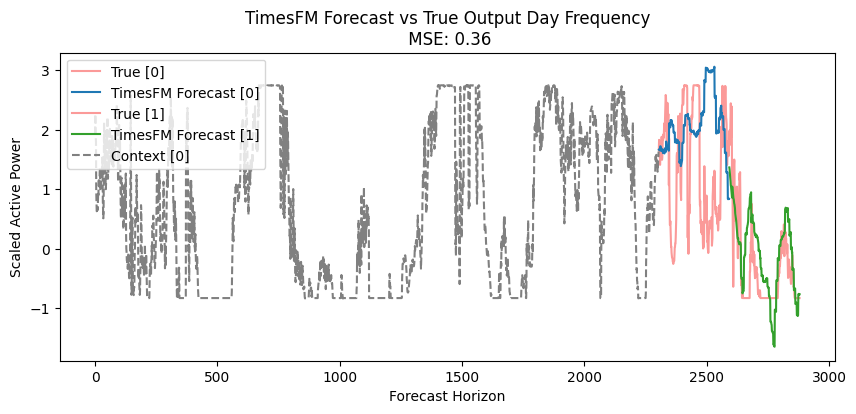

In [21]:
mean_forecast, ols_forecast = model.forecast_with_covariates(inputs=inputs, 
                                                                  dynamic_numerical_covariates=cova, 
                                                                  freq=[0,]*len(inputs))
mse = jnp.mean((mean_forecast - outputs) ** 2, axis=-1)
print("MSE Error: ", mse.mean())

cmap = plt.get_cmap('Paired')
plt.figure(figsize=(10, 4))
plt.plot(np.arange(context_length, context_length+horizon_length), outputs[0], label='True [0]', color=cmap(4))
plt.plot(np.arange(context_length, context_length+horizon_length), mean_forecast[0], label='TimesFM Forecast [0]', color=cmap(1))
# plt.plot(np.arange(context_length, context_length+horizon_length), ols_forecast[0], label='OLS Forecast [0]', color=cmap(1), linestyle='--')
# plt.fill_between(np.arange(context_length, context_length+horizon_length),
#                  quantile_forecast[0, :, 1], quantile_forecast[0, :, 9],
#                  color=cmap(0), alpha=0.8, label='Uncertainty [0]')
plt.plot(np.arange(context_length+horizon_length, context_length+2*horizon_length), outputs[1], label='True [1]', color=cmap(4))
plt.plot(np.arange(context_length+horizon_length, context_length+2*horizon_length), mean_forecast[1], label='TimesFM Forecast [1]', color=cmap(3))
# plt.plot(np.arange(context_length+horizon_length, context_length+2*horizon_length), ols_forecast[1], label='OLS Forecast [1]', color=cmap(3), linestyle='--')
# plt.fill_between(np.arange(context_length+horizon_length, context_length+2*horizon_length),
#                  quantile_forecast[1, :, 1], quantile_forecast[1, :, 9],
#                  color=cmap(2), alpha=0.5, label='Uncertainty [1]')
plt.plot(inputs[0], label='Context [0]', linestyle='--', color='gray')
plt.xlabel('Forecast Horizon')
plt.ylabel('Scaled Active Power')
plt.title('TimesFM Forecast vs True Output Day Frequency\n MSE: {:.2f}'.format(mse.mean()))
plt.legend()

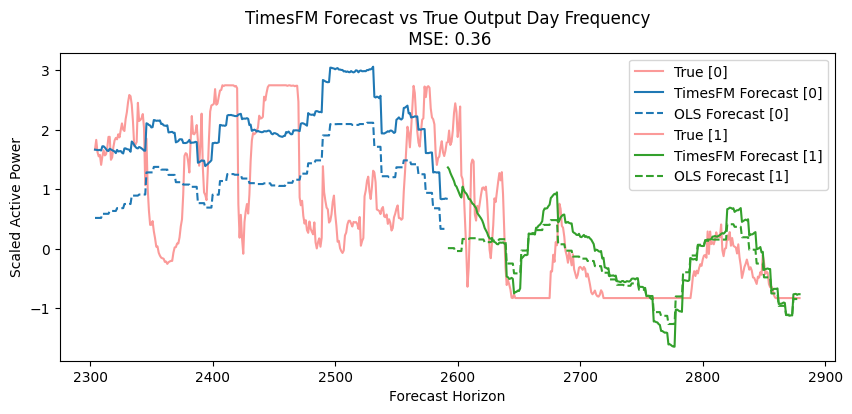

In [22]:
plt.figure(figsize=(10, 4))
plt.plot(np.arange(context_length, context_length+horizon_length), outputs[0], label='True [0]', color=cmap(4))
plt.plot(np.arange(context_length, context_length+horizon_length), mean_forecast[0], label='TimesFM Forecast [0]', color=cmap(1))
plt.plot(np.arange(context_length, context_length+horizon_length), ols_forecast[0], label='OLS Forecast [0]', color=cmap(1), linestyle='--')
# plt.fill_between(np.arange(context_length, context_length+horizon_length),
#                  quantile_forecast[0, :, 1], quantile_forecast[0, :, 9],
#                  color=cmap(0), alpha=0.8, label='Uncertainty [0]')
plt.plot(np.arange(context_length+horizon_length, context_length+2*horizon_length), outputs[1], label='True [1]', color=cmap(4))
plt.plot(np.arange(context_length+horizon_length, context_length+2*horizon_length), mean_forecast[1], label='TimesFM Forecast [1]', color=cmap(3))
plt.plot(np.arange(context_length+horizon_length, context_length+2*horizon_length), ols_forecast[1], label='OLS Forecast [1]', color=cmap(3), linestyle='--')
# plt.fill_between(np.arange(context_length+horizon_length, context_length+2*horizon_length),
#                  quantile_forecast[1, :, 1], quantile_forecast[1, :, 9],
#                  color=cmap(2), alpha=0.5, label='Uncertainty [1]')
plt.xlabel('Forecast Horizon')
plt.ylabel('Scaled Active Power')
plt.title('TimesFM Forecast vs True Output Day Frequency\n MSE: {:.2f}'.format(mse.mean()))
plt.legend()

## analyses TimesFM

In [23]:
from jax.tree_util import tree_flatten, tree_flatten_with_path
model._train_state.mdl_vars['params']
params, tree_def = tree_flatten_with_path(model._train_state.mdl_vars['params'])
n_params = sum(p.size for _, p in params)
n_bytes = sum(p.nbytes for _, p in params)
print(f"Number parameters {n_params/1000/1000:.2f}M")
print(f"Storage parameters {4*n_params/1024/1024/1024:.2f}GB")
print(f"Storage parameters {n_bytes/1024/1024/1024:.2f}GB")

Number parameters 498.83M
Storage parameters 1.86GB
Storage parameters 1.86GB


In [24]:
model._train_state.mdl_vars['params'].keys()

dict_keys(['freq_emb', 'horizon_ff_layer', 'input_ff_layer', 'stacked_transformer_layer'])

In [25]:
model_test = model._model.bind(
    model._train_state.mdl_vars['params'])

In [26]:
context_length

2304

In [8]:
input_ts = {}
input_ts['input_ts'], input_ts['input_padding'], input_ts['freq'], _ = model._preprocess(inputs[:512], freq=[0,]*len(inputs[:512]))
input_ts['input_padding'] = input_ts['input_padding'][:, :input_ts['input_ts'].shape[1]]
input_ts['input_ts'].shape, input_ts['input_padding'].shape, input_ts['freq'].shape

((512, 2304), (512, 2304), (512, 1))

In [44]:
sample_inputs = model._get_sample_inputs()
sample_inputs['input_ts'].shape, sample_inputs['input_padding'].shape, sample_inputs['freq'].shape

((256, 2432), (256, 2432), (256, 1))

In [46]:
# Ensure the correct JAX key function is used
key = jax.random.PRNGKey(0)

# # Ensure the sample inputs are correctly provided
# sample_inputs = model._get_sample_inputs()
# print("sample_inputs: ", sample_inputs['input_ts'].shape)

model_def = model_test.tabulate(jax.random.PRNGKey(0), input_ts, compute_flops=False, compute_vjp_flops=False, console_kwargs={"width": 200})
# Write the tree structure of model parameters to a file
with open("model_tree_structure.ansi", "w") as f:
    f.write(str(model_def))
print(model_def)



                                                                                    PatchedTimeSeriesDecoder Summary                                                                                    
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ path                                             ┃ module                                   ┃ inputs                             ┃ outputs                              ┃ params                     ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│                                                  │ PatchedTimeSeriesDecoder (init)          │ - uint32[2]                        │ params:                              │                        

From File
https://vscode.dev/github/doldd/Time_Transformer/blob/mainns/lib/python3.10/site-packages/timesfm/patched_decoder.py   

    patched_inputs = es.jax_einshape("b(np)->bnp", input_ts, p=self.patch_len)
    patched_pads = es.jax_einshape("b(np)->bnp",
                                   input_padding,
                                   p=self.patch_len)
    patched_inputs = jnp.where(
        jnp.abs(patched_pads - 1.0) < _TOLERANCE, 0.0, patched_inputs)
    patched_pads = jnp.where(
        jnp.abs(patched_inputs - PAD_VAL) < _TOLERANCE, 1, patched_pads)
    patched_inputs, stats = self._forward_transform(patched_inputs,
                                                    patched_pads)

    # B x N x D
    patched_inputs = patched_inputs * (1.0 - patched_pads)
    concat_inputs = jnp.concatenate([patched_inputs, patched_pads], axis=-1)
    model_input = self.input_ff_layer(concat_inputs)

In [63]:
# praxis apply function https://github.com/google/praxis/blob/41191d22b702d5f86a1dd1a72e89c0d030c08aec/praxis/base_layer.py#L1952 
input_for_transformer, patched_padding, stats, patched_inputs = model._model.apply(model._train_state.mdl_vars,input_ts['input_ts'], input_ts['input_padding'], method=model._model._preprocess_input)

print("input sequence length: ", input_ts['input_ts'].shape)
print(f"input for Transformer has Shape: (BatchShape, Tokens, embedding_dim)", input_for_transformer.shape)
print(f"One Token is calculated out of 32 timestamps => 2304/32 = {2304//32}")
input_for_transformer.shape

input sequence length:  (512, 2304)
input for Transformer has Shape: (BatchShape, Tokens, embedding_dim) (512, 72, 1280)
One Token is calculated out of 32 timestamps => 2304/32 = 72


(512, 72, 1280)

In [8]:
len(jnp.ones((23,3)))

23

In [ ]:
class timesfmWrapper:
    def __init__(self, model, frequency=0, autoregressive=False):
        self.model = model
        self.freq = frequency  # Frequency of the model, e.g., 0 for daily data
        self.autoregressive = autoregressive  # Set to True if you want to use autoregressive decoding

    def _prepare_data(self, x):
        # Prepare the data for the model, e.g., add frequency information
        freq = jnp.full((len(x),1), self.freq, dtype=jnp.int32)
        input_ts = {}
        input_ts['input_ts'], input_ts['input_padding'], input_ts['freq'], _ = self.model._preprocess(x, freq)
        input_ts['input_padding'] = input_ts['input_padding'][:, :input_ts['input_ts'].shape[1]]
        return input_ts

    def apply(self, params, x, train=False, mutuable=False):
        param_model = model._model.bind(params)
        if self.autoregressive:
            # use decode of patched_decoder model to run autoregressive decoding for larger horzion lengths than output_patch_len=128
            freq = jnp.full((len(x),1), self.freq, dtype=jnp.int32)
            input_ts = {}
            input_ts['input_ts'], input_ts['input_padding'], input_ts['freq'], _ = self.model._preprocess(x, freq)
            return param_model.decode(inputs=input_ts,
                                      horizon_len=w_model.model.horizon_len)
        else:
            # use __call__ of patched_decoder model to run single forward pass with horizon length equal to output_patch_len=128
            input_ts = self._prepare_data(x)
            fprop_outputs = param_model(input_ts)['output_ts'] # shape (BatchShape, Timeseries, output_dim) output_dim is 10 for quantile regression tasks
            o_batch_len = w_model.model.output_patch_len
            return (fprop_outputs[:, -1, :o_batch_len, 0], fprop_outputs[:, -1, :o_batch_len, 0])

    def init(self, key, x):
        return self.model._model.init(key, self._prepare_data(x))
    
w_model = timesfmWrapper(model, frequency=0, autoregressive=True)
# init_params = w_model.init(jax.random.PRNGKey(0), inputs[:256])
w_model.apply(model._train_state.mdl_vars, inputs[:256], train=False, mutuable=False)[1].shape

(256, 288, 10)

In [18]:
w_model.model.horizon_len

288

In [ ]:
model._train_state.mdl_vars

{'freq_emb': {'emb_var': array([[ 0.0949898 , -0.03221982, -0.05389089, ..., -0.12183157,
           0.0885485 ,  0.00628475],
         [ 0.1048953 , -0.06185808,  0.08863156, ..., -0.02630784,
           0.03747937, -0.11830091],
         [ 0.01713165,  0.0722609 ,  0.02598771, ...,  0.08966534,
           0.06762086, -0.05112475]], dtype=float32)},
 'horizon_ff_layer': {'hidden_layer': {'bias': {'b': array([-0.01921851, -0.0471644 , -0.01817104, ..., -0.04556634,
           -0.03470363, -0.0344962 ], dtype=float32)},
   'linear': {'w': array([[ 0.03655547,  0.01540517, -0.04364083, ..., -0.01548328,
            -0.07610342, -0.01170967],
           [-0.09271821,  0.03270156, -0.04432858, ..., -0.04764687,
            -0.02035581,  0.01599862],
           [-0.01994627, -0.01941311, -0.03292211, ..., -0.03584745,
            -0.0588451 ,  0.00292652],
           ...,
           [-0.00885989,  0.00132444, -0.01011136, ...,  0.05623165,
             0.06467367, -0.02525525],
           [

In [ ]:
init_params

{'params': {'freq_emb': {'emb_var': Array([[ 0.05670918, -0.06346569, -0.00884514, ...,  0.06692699,
            0.01625024,  0.05809166],
          [ 0.03873365, -0.00757147, -0.06414795, ..., -0.01266743,
            0.04182195,  0.01406877],
          [-0.02599056,  0.03187456, -0.02588798, ..., -0.06534581,
            0.00273779,  0.04752111]], dtype=float32)},
  'horizon_ff_layer': {'hidden_layer': {'bias': {'b': Array([0., 0., 0., ..., 0., 0., 0.], dtype=float32)},
    'linear': {'w': Array([[-0.02553046,  0.00109812, -0.03629407, ...,  0.0376229 ,
             -0.01147938,  0.02286378],
            [ 0.03687354, -0.0477239 ,  0.03107841, ...,  0.00287064,
             -0.03496431,  0.01616701],
            [-0.01688471, -0.04219368,  0.00449784, ..., -0.00772341,
              0.01821407,  0.01209476],
            ...,
            [ 0.02214012,  0.02678768,  0.00862893, ...,  0.04385568,
             -0.04471615, -0.01041054],
            [-0.01186704, -0.00753827,  0.04699129,

In [10]:
w_model._prepare_data(inputs[:10])['input_ts'].shape

(256, 2304)

In [77]:
import gc
gc.collect()


7976

## Define own transformer

In [2]:
from jax import numpy as jnp
from flax import linen as nn

In [3]:
# prepare the data
input_patch_length = 32
context_len=input_patch_length*4
horizon_len=6*24

def df_to_matrix(df, input_patch_length, context_len, horizon_len):
    df_sub = df[(df['TurbID'] == 57)].copy()
    df_sub.sort_values('Tmstamp', inplace=True)
    X, y = [], []
    for start in range(0, len(df_sub) - (context_len + horizon_len), horizon_len):
        X.append(df_sub['Patv'].iloc[start:(context_end := start + context_len)].values.reshape(-1, input_patch_length))
        y.append(df_sub['Patv'].iloc[context_end:(context_end+horizon_len)].values)

    X = np.stack(X)
    y = np.stack(y)
    return X, y

X, y = df_to_matrix(df_train, input_patch_length, context_len, horizon_len)
X_val, y_val = df_to_matrix(df_val, input_patch_length, context_len, horizon_len)
X.shape, y.shape, X_val.shape, y_val.shape

NameError: name 'df_train' is not defined

In [ ]:
class TimeTransform(nn.Module):
    empedding_dim: int = 512
    horizon_len: int = 6*24
    num_heads: int = 8
    num_stacking_layers: int = 3

    @nn.compact
    def __call__(self, x):
        # Example Transformer Encoder architecture

        
        # Embedding layer
        x = nn.Dense(self.empedding_dim)(x)  
        # Positional encoding
        pos = jnp.arange(x.shape[1])[:, None]
        i = jnp.arange(self.empedding_dim)[None, :]
        angle_rates = 1 / jnp.power(10000, (2 * (i // 2)) / jnp.float32(self.empedding_dim))
        pos_encoding = pos * angle_rates
        pos_encoding = jnp.where(i % 2 == 0, jnp.sin(pos_encoding), jnp.cos(pos_encoding))
        x += pos_encoding
        # Stacking layers
        for _ in range(self.num_stacking_layers):
            x_tmp = nn.MultiHeadDotProductAttention(num_heads=self.num_heads, qkv_features=self.empedding_dim, )(x)
            x = nn.LayerNorm()(x+x_tmp)
        x = nn.Dense(self.horizon_len)(x)  # Another dense layer
        return x[...,-1,:]
    
# Create a TimeTransform instance
time_transform = TimeTransform(empedding_dim=512, horizon_len=horizon_len, num_heads=32)


In [4]:
init_rng = random.PRNGKey(0)
params = time_transform.init(init_rng, X[0:1])  # Initialize the model
params['params']

2025-06-23 14:36:32.373926: E external/xla/xla/stream_executor/cuda/cuda_dnn.cc:536] Could not create cudnn handle: CUDNN_STATUS_INTERNAL_ERROR
2025-06-23 14:36:32.374069: E external/xla/xla/stream_executor/cuda/cuda_dnn.cc:540] Memory usage: 16599613440 bytes free, 16733831168 bytes total.
2025-06-23 14:36:32.402598: E external/xla/xla/stream_executor/cuda/cuda_dnn.cc:536] Could not create cudnn handle: CUDNN_STATUS_INTERNAL_ERROR
2025-06-23 14:36:32.402757: E external/xla/xla/stream_executor/cuda/cuda_dnn.cc:540] Memory usage: 16599613440 bytes free, 16733831168 bytes total.


XlaRuntimeError: FAILED_PRECONDITION: DNN library initialization failed. Look at the errors above for more details.

In [29]:
print(time_transform.tabulate(init_rng, X[0:1], 
                   compute_flops=False, compute_vjp_flops=False, console_kwargs={"width": 200}))


                                                            TimeTransform Summary                                                             
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ path                                 ┃ module                       ┃ inputs             ┃ outputs            ┃ params                     ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│                                      │ TimeTransform                │ float32[1,4,16]    │ float32[1,144]     │                            │
├──────────────────────────────────────┼──────────────────────────────┼────────────────────┼────────────────────┼────────────────────────────┤
│ Dense_0                              │ Dense                        │ float32[1,4,16]    │ float32[1,4,512]   │ bias: float32[512]         

Epoch 1, Loss: 1.1252009868621826, Val Loss: 0.9594771265983582
Epoch 2, Loss: 0.9165289998054504, Val Loss: 0.9299868941307068
Epoch 3, Loss: 0.9033244848251343, Val Loss: 0.9422181844711304
Epoch 4, Loss: 0.8866336345672607, Val Loss: 0.9211004972457886
Epoch 5, Loss: 0.8665212392807007, Val Loss: 0.9590048789978027
Epoch 6, Loss: 0.8391640186309814, Val Loss: 0.9841262102127075
Epoch 7, Loss: 0.845054030418396, Val Loss: 0.9929018020629883
Epoch 8, Loss: 0.8337371349334717, Val Loss: 0.9851952195167542
Epoch 9, Loss: 0.7973537445068359, Val Loss: 1.057815670967102
Epoch 10, Loss: 0.7718349099159241, Val Loss: 1.0467344522476196
Epoch 11, Loss: 0.7868770360946655, Val Loss: 1.0967447757720947
Epoch 12, Loss: 0.7394166588783264, Val Loss: 1.1141914129257202
Epoch 13, Loss: 0.712451159954071, Val Loss: 1.1782327890396118
Epoch 14, Loss: 0.6715163588523865, Val Loss: 1.1412813663482666
Epoch 15, Loss: 0.6297942996025085, Val Loss: 1.168808937072754
Epoch 16, Loss: 0.6087580323219299, Va

Text(0, 0.5, 'Loss')

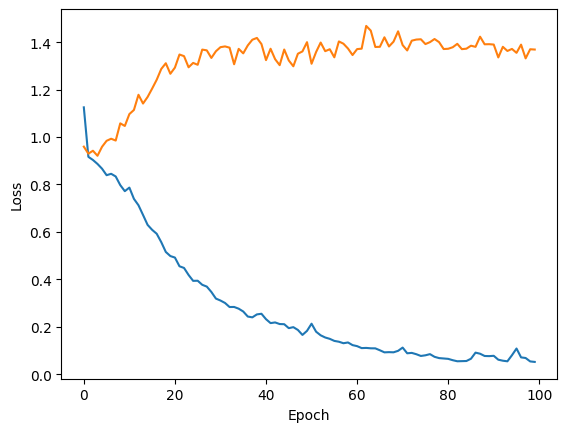

In [30]:
import optax
from jax import grad, jit, value_and_grad
from jax import random

import jax.numpy as jnp

init_key = random.PRNGKey(0)
params = time_transform.init(init_key, X[0:1])  # Initialize the model

# Define the loss function
def loss_fn(params, batch):
    inputs, targets = batch
    predictions = time_transform.apply(params, inputs)
    # print(predictions.shape, targets.shape)
    loss = jnp.mean((predictions - targets) ** 2)
    return loss

# Define the update function
@jit
def update(params, opt_state, batch):
    loss, grads = value_and_grad(loss_fn)(params, batch)
    updates, opt_state = optimizer.update(grads, opt_state)
    params = optax.apply_updates(params, updates)
    return params, opt_state, loss

# Initialize the optimizer
learning_rate = 2e-4
optimizer = optax.adam(learning_rate)
opt_state = optimizer.init(params)

# Training loop
num_epochs = 100
batch_size = X.shape[0] // 20
train_loss = []
val_loss = []
for epoch in range(num_epochs):
    loss_e = []
    perm_key, init_key = random.split(init_key)
    permute = jax.random.permutation(perm_key, len(X))
    xx, yy = X[permute], y[permute]
    for start in range(0, len(X), batch_size):
        end = start + batch_size
        batch = (xx[start:end], yy[start:end])
        params, opt_state, loss = update(params, opt_state, batch)
        loss_e.append(loss)
    
    # Compute and print the loss for the current epoch
    epoch_loss = jnp.array(loss_e).mean()
    train_loss.append(epoch_loss)
    v_loss = loss_fn(params, (X_val, y_val))
    val_loss.append(v_loss)
    print(f'Epoch {epoch + 1}, Loss: {epoch_loss}, Val Loss: {v_loss}')

plt.plot(train_loss)
plt.plot(val_loss)
plt.xlabel('Epoch')
plt.ylabel('Loss')

In [61]:
X.shape

(557, 30, 32)

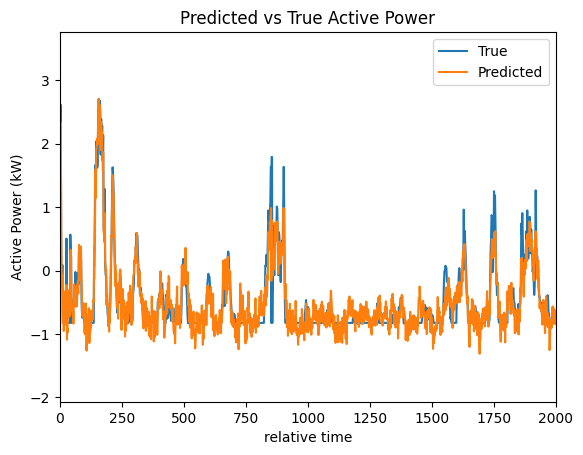

In [78]:
# visualize the prediction
predictions = time_transform.apply(params, X)
plt.plot(y.flatten(), label='True')
plt.plot(predictions.flatten(), label='Predicted')
plt.legend()
plt.xlabel('relative time')
plt.ylabel('Active Power (kW)')
plt.title('Predicted vs True Active Power')
plt.xlim(0, 2000)
plt.show()

Text(0, 0.5, 'scaled Active Power')

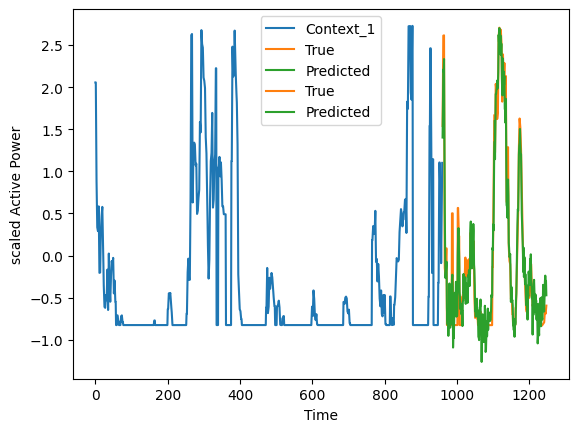

In [75]:
# visualize the prediction for a single day

predictions = time_transform.apply(params, X)
time = np.arange(0, context_len, 1)
plt.plot(time, X[0].flatten(), label='Context_1')
# plt.plot(time+horizon_len, X[1].flatten(), label='Context_2')
time = np.arange(0, horizon_len, 1)
plt.plot(time+context_len, y[0], label='True', color=plt.get_cmap('tab10')(1))
plt.plot(time+context_len, predictions[0], label='Predicted', color=plt.get_cmap('tab10')(2))
plt.plot(time+context_len+horizon_len, y[1], label='True', color=plt.get_cmap('tab10')(1))
plt.plot(time+context_len+horizon_len, predictions[1], label='Predicted', color=plt.get_cmap('tab10')(2))
plt.legend()
plt.xlabel('Time')
plt.ylabel('scaled Active Power')

In [80]:
# with new turbine
df_sub = df[(df['TurbID'] == 120)].copy()
df_sub.sort_values('Tmstamp', inplace=True)
X, y = [], []
for start in range(0, len(df_sub) - (context_len + horizon_len), horizon_len):
    X.append(df_sub['Patv'].iloc[start:(context_end := start + context_len)].values.reshape(-1, input_patch_length))
    y.append(df_sub['Patv'].iloc[context_end:(context_end+horizon_len)].values)

X = np.stack(X)
y = np.stack(y)
X.shape, y.shape


((558, 30, 32), (558, 144))

Text(0, 0.5, 'scaled Active Power')

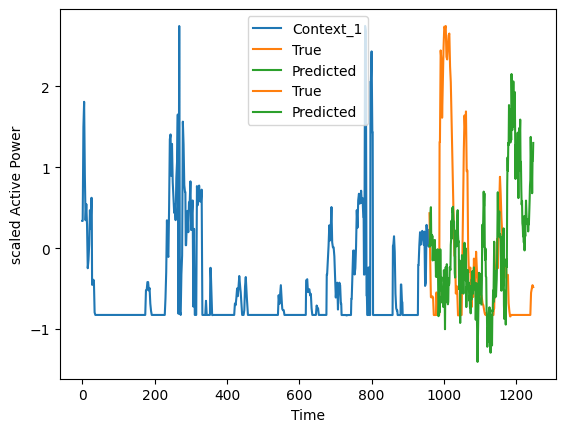

In [81]:
predictions = time_transform.apply(params, X)
time = np.arange(0, context_len, 1)
plt.plot(time, X[0].flatten(), label='Context_1')
# plt.plot(time+horizon_len, X[1].flatten(), label='Context_2')
time = np.arange(0, horizon_len, 1)
plt.plot(time+context_len, y[0], label='True', color=plt.get_cmap('tab10')(1))
plt.plot(time+context_len, predictions[0], label='Predicted', color=plt.get_cmap('tab10')(2))
plt.plot(time+context_len+horizon_len, y[1], label='True', color=plt.get_cmap('tab10')(1))
plt.plot(time+context_len+horizon_len, predictions[1], label='Predicted', color=plt.get_cmap('tab10')(2))
plt.legend()
plt.xlabel('Time')
plt.ylabel('scaled Active Power')

### Jax Transformer example

In [ ]:
from flax import linen as nn
import jax

# Flax Transformer Example
class SimpleFlaxTransformer(nn.Module):
    num_heads: int = 2
    qkv_features: int = 8 # (h*dk)
    out_f: int = 3

    @nn.compact
    def __call__(self, x, mask=None):
        x = nn.MultiHeadDotProductAttention(num_heads=self.num_heads, qkv_features=self.qkv_features, out_features=self.out_f)(x, mask=mask)
        return x

# Example input
key = jax.random.PRNGKey(0)
x = jax.random.normal(key, (2, 20, 9))  # (batch, seq, in_features)
model = SimpleFlaxTransformer()
params = model.init(key, x)

# Create a mask (e.g., mask out last 5 positions in the sequence)
# Shape: (batch, num_heads, seq_len, seq_len)
mask = jnp.ones((x.shape[0], model.num_heads, x.shape[1], x.shape[1]), dtype=jnp.float32)  
mask = mask.at[:, :, -5:].set(0) 

output = model.apply(params, x, mask=mask)
print("Flax Transformer input shape:", x.shape)
print("Flax Transformer output shape:", output.shape)

print("Flax Transformer parameters:")
for k,v in jax.tree_util.tree_flatten_with_path(params['params'])[0]:
    name = f"{k[1].key}/{k[2].key}"
    print(f"\t{name},\t{v.shape}")

Flax Transformer input shape: (2, 20, 9)
Flax Transformer output shape: (2, 20, 3)
Flax Transformer parameters:
	key/bias,	(2, 4)
	key/kernel,	(9, 2, 4)
	out/bias,	(3,)
	out/kernel,	(2, 4, 3)
	query/bias,	(2, 4)
	query/kernel,	(9, 2, 4)
	value/bias,	(2, 4)
	value/kernel,	(9, 2, 4)


In [ ]:
from jax import numpy as jnp
from flax import linen as nn

# Flax Transformer Example
class SimpleFlaxTransformer(nn.Module):
    embed_dim: int = 16
    num_heads: int = 2

    @nn.compact
    def __call__(self, x):
        x = nn.Dense(self.embed_dim)(x)
        x = nn.SelfAttention(num_heads=self.num_heads)(x)
        return x

# Example input
key = jax.random.PRNGKey(0)
x = jax.random.normal(key, (2, 8, 4))  # (batch, seq, features)
model = SimpleFlaxTransformer()
params = model.init(key, x)
output = model.apply(params, x)
print("Flax Transformer output shape:", output.shape)

# JAX "Transformer" Example (single attention layer)
def simple_jax_attention(x):
    # x: (batch, seq, features)
    key = jax.random.PRNGKey(42)
    q_w = jax.random.normal(key, (x.shape[-1], x.shape[-1]))
    k_w = jax.random.normal(key, (x.shape[-1], x.shape[-1]))
    v_w = jax.random.normal(key, (x.shape[-1], x.shape[-1]))
    Q = jnp.einsum('bsi,ij->bsj', x, q_w)
    K = jnp.einsum('bsi,ij->bsj', x, k_w)
    V = jnp.einsum('bsi,ij->bsj', x, v_w)
    attn_scores = jnp.einsum('bsi,bsj->bij', Q, K) / jnp.sqrt(x.shape[-1])
    attn_weights = jax.nn.softmax(attn_scores, axis=-1)
    out = jnp.einsum('bij,bsj->bsi', attn_weights, V)
    return out

out_jax = simple_jax_attention(x)
print("JAX attention output shape:", out_jax.shape)

Flax Transformer output shape: (2, 8, 16)
Numpy attention output shape: (2, 8, 4)
